# Tarea 4 — Aplicación Árboles de Decisión, RF y AdaBoost

## Pronóstico del nivel de carga eléctrica con consumo previo en DAEWOO Steel Co.

**Proyecto:** *Sistema Predictivo de Gestión Energética y Alertas Operativas para DAEWOO Steel Co. mediante Minería de Datos y LangChain*

---

Integrantes: 


Académico:

Asignatura:

Sección:

Repositorio:
https://github.com/JoMi-MorV/Proyecto_Mineria_de_Datos_Daewoo

---

### Resumen

Este trabajo construye y compara cuatro tipos de modelos los cuales son árboles de decisión (con los criterios Gini, entropía y error de clasificación, y profundidades de 3 y 5 niveles), Random Forest, AdaBoost y redes bayesianas, para **pronosticar con una hora de anticipación el nivel de carga de la planta** (liviana, media o máxima), a partir de lo que se conoce en el instante actual: el consumo reciente, el nivel de carga actual, las mediciones eléctricas y el calendario del momento que se pronostica. Todos los modelos se entrenan con los datos de enero a septiembre de 2018 y se evalúan con los de octubre a diciembre.

Como un pronóstico solo es útil si supera a reglas muy simples, cada modelo se compara con tres **líneas base**: asumir que la carga no cambiará (*persistencia*), usar la carga típica de esa hora y tipo de día (*calendario típico*) y responder siempre la clase más frecuente. Además de la exactitud, se mide la **capacidad de anticipar las subidas a carga máxima**, que es lo que requiere un sistema de alertas.

### Resultados en síntesis

El **Random Forest** fue el modelo con mejor desempeño: acierta el **95,2 %** de los pronósticos de prueba frente al 77,1 % de la persistencia (**+18,1 puntos**), con F1 macro de 0,932 frente a 0,706. Anticipa **el 75,1 % de las subidas a carga máxima** (604 de 804) y cuando avisa *carga máxima* acierta el 89,2 % de las veces. Le siguen AdaBoost (94,2 %), el árbol de decisión Gini de profundidad 5 (89,8 %) y la red bayesiana (84,3 %). El factor que lo explica es el **consumo previo**: con solo el calendario, el mismo bosque alcanza 72,2 %.


## 1. Introducción y contexto

### 1.1 El problema y su utilidad real

La planta de DAEWOO Steel Co. registra su consumo eléctrico **cada 15 minutos** durante todo 2018 (**35.040 mediciones**). Cada medición incluye el consumo de energía, variables eléctricas (potencias reactivas y factores de potencia), el momento del día y del tipo de día, y una etiqueta llamada `Load_Type` que describe el nivel de carga de la planta:

- **Light_Load** — carga liviana (poca maquinaria funcionando);
- **Medium_Load** — carga media;
- **Maximum_Load** — carga máxima (la planta opera a plena capacidad).

Los periodos de **carga máxima** son los de mayor exigencia para la planta y, en general, los de mayor costo: las tarifas eléctricas industriales suelen penalizar la demanda punta. **Saber con una hora de anticipación que la planta entrará en carga máxima** permite actuar antes de que ocurra, por ejemplo reprogramando procesos que pueden esperar, escalonando el encendido de equipos o compensando la energía reactiva. Un sistema que solo reconoce la carga máxima cuando ya está ocurriendo llega tarde.

Por eso este trabajo plantea un problema de **pronóstico**:

Con la información disponible ahora (instante t), ¿qué nivel de carga habrá dentro de 1 hora (instante t + 1 h)?

### 1.2 Objetivos de la tarea

**Objetivo general.** Aplicar y comparar árboles de decisión, Random Forest, AdaBoost y redes bayesianas para pronosticar el nivel de carga de la planta, evaluando su desempeño con conjuntos de entrenamiento y de prueba y contra reglas de referencia simples.

**Objetivos específicos.**

1. **Árboles de decisión:** construirlos con tres criterios de división (Gini, entropía y error de clasificación), compararlos y graficarlos con 3 y 5 niveles de profundidad.
2. **Random Forest:** entrenarlo y analizar si combinar muchos árboles mejora el desempeño de un árbol individual.
3. **AdaBoost:** entrenarlo y analizar el efecto de encadenar árboles pequeños que corrigen los errores de los anteriores.
4. **Redes bayesianas:** construirlas con tres estructuras (Naive Bayes, experta y aprendida de los datos) y analizar las relaciones entre variables y las probabilidades que entregan.
5. **Evaluación:** medir todos los modelos con un conjunto de **entrenamiento** y otro de **prueba**, y compararlos con líneas base.
6. **Aporte de la información:** medir cuánto mejora el pronóstico al incorporar el consumo previo y cómo cambia el desempeño al pronosticar más lejos en el tiempo.
7. **Utilidad para el proyecto:** determinar qué modelo conviene para el sistema de alertas y qué limitaciones tiene.

**Relación con el proyecto.** El sistema del proyecto busca anticipar el comportamiento energético de la planta y generar alertas operativas. Esta tarea es la etapa de modelado de ese sistema: sus modelos y hallazgos serán la base del componente predictivo.

### 1.3 Cómo funciona un árbol de decisión: un ejemplo aplicado

Un árbol de decisión es un **cuestionario de preguntas de sí o no** que se responden en orden, como lo haría un ingeniero de la planta. En este caso, un recorrido posible sería:

1. *¿El consumo actual es mayor que 49 kWh?* — si es **sí**, se sigue por una rama; si es **no**, por otra.
2. *¿El consumo subió más de 10 kWh en la última hora?*
3. *¿La hora que se pronostica es entre las 12 y las 18 h de un día hábil?*
4. Se llega a una **hoja** con la respuesta: *"dentro de una hora, lo más probable es carga máxima"*.

(Los valores de este ejemplo son ilustrativos; los umbrales reales los determina el modelo con los datos.)

La diferencia con un experto humano es que el árbol **construye el cuestionario por sí solo**: prueba miles de preguntas posibles y conserva las que **mejor separan** los tres niveles de carga. Una pregunta es buena cuando los grupos que genera quedan **más homogéneos**, es decir, dominados por un solo nivel de carga. Esa homogeneidad se mide con los tres criterios que pide la tarea:

| Criterio | Fórmula | Interpretación |
|---|---|---|
| **Gini** | $1-\sum_k p_k^2$ | Probabilidad de equivocarse si se etiqueta al azar según las proporciones del grupo. |
| **Entropía** | $-\sum_k p_k \log_2 p_k$ | Grado de "desorden" o incertidumbre del grupo. |
| **Error de clasificación** | $1-\max_k p_k$ | Proporción del grupo que se clasificaría mal si se respondiera siempre la clase mayoritaria. |

donde $p_k$ es la proporción de mediciones del nivel de carga $k$ dentro del grupo. Los tres valen **0 cuando el grupo es puro** y crecen a medida que el grupo está más mezclado. Cada camino de la raíz a una hoja es una **regla legible** ("si ocurre A y B, entonces C"), que el personal de la planta puede revisar y discutir.

### 1.4 Los cuatro enfoques

| Enfoque | Idea central | Analogía |
|---|---|---|
| **Árbol de decisión** | Un único cuestionario de preguntas por rangos de valores. | Un experto que sigue su protocolo. |
| **Random Forest** | Muchos árboles, cada uno entrenado con una muestra distinta de los datos; la respuesta final se decide **por votación**. | Un comité de expertos que votan. |
| **AdaBoost** | Árboles muy pequeños entrenados **en secuencia**, donde cada uno se concentra en los casos que los anteriores clasificaron mal. | Un equipo en que cada nuevo integrante corrige lo que los demás no vieron. |
| **Red bayesiana** | Un grafo que representa **qué variables influyen en cuáles**, con las probabilidades asociadas. | Un diagrama de causas y efectos con porcentajes. |

Los tres primeros buscan acertar. La red bayesiana, además, **cuantifica la incertidumbre** y permite preguntar *"¿qué probabilidad hay de carga máxima dentro de una hora si ahora la carga es media y el consumo viene subiendo?"*, lo que la hace especialmente útil para un sistema de alertas.

## 2. Metodología

### 2.1 Definición del pronóstico

- **Instante de origen (t):** el momento en que se hace el pronóstico. Solo se puede usar información de t y de instantes anteriores.
- **Horizonte:** **4 intervalos de 15 minutos = 1 hora**. Es un plazo suficiente para reaccionar, pero lo bastante corto para que el pronóstico sea razonable. En la sección 10 se evalúan otros horizontes.
- **Objetivo (`y`):** el nivel de carga (`Load_Type`) en el instante t + 1 h.

### 2.2 Variables utilizadas

Todas las variables son **conocidas en el instante t**, de modo que el modelo podría usarlas en tiempo real:

| Grupo | Variable | Qué representa y por qué se usa |
|---|---|---|
| **Consumo previo** | `Consumo_t` | Consumo actual (kWh). Es el mejor indicador del estado presente de la planta. |
| | `Consumo_t-15min` | Consumo de hace 15 minutos: captura la inercia de corto plazo. |
| | `Consumo_t-1h` | Consumo de hace 1 hora: permite ver hacia dónde va el consumo. |
| | `Consumo_t-24h` | Consumo a la misma hora de ayer: captura el ciclo diario de la planta. |
| | `Variacion_1h` | Cambio del consumo en la última hora (actual − hace 1 h): resume la **tendencia** (subiendo o bajando). |
| | `Carga_actual` | Nivel de carga actual (liviana, media o máxima): el punto de partida del pronóstico. |
| **Mediciones eléctricas** | `Lagging_Current_Reactive.Power_kVarh` | Energía reactiva inductiva (motores, hornos, transformadores). |
| | `Leading_Current_Reactive_Power_kVarh` | Energía reactiva capacitiva. |
| | `Lagging_Current_Power_Factor` | Factor de potencia inductivo (eficiencia con que se usa la energía). |
| | `Leading_Current_Power_Factor` | Factor de potencia capacitivo. |
| **Calendario del destino** | `Destino_WeekStatus_bin` | Tipo de día del instante que se pronostica (0 hábil, 1 fin de semana). |
| | `Destino_NSM_sin`, `Destino_NSM_cos` | Hora del instante que se pronostica, con seno y coseno. |

**Por qué el calendario es del instante pronosticado.** La hora y el día de la semana de "dentro de una hora" se conocen de antemano, por lo que usarlos no es hacer trampa. Lo que importa para la carga futura es *cuándo* ocurrirá, no cuándo se hace el pronóstico.

**Por qué la hora se transforma con seno y coseno.** Para un computador, las 23:45 (23,75) y las 00:15 (0,25) parecen muy distantes, aunque solo los separan 30 minutos. Al representar la hora como un punto sobre un reloj —con su seno y su coseno— la medianoche queda junto a la medianoche y el día se interpreta como un ciclo.

### 2.3 Decisiones de diseño

- **El consumo actual sí se usa, pero solo el pasado.** `Load_Type` se define a partir del consumo medido. Si se usara el consumo del *mismo instante que se pronostica*, el problema sería trivial (la etiqueta se deduce de él). Pero el consumo de **instantes anteriores o del actual** está disponible en tiempo real y es una fuente legítima de información para pronosticar lo que viene. Esa es la diferencia entre *reconocer* la carga y *pronosticarla*.
- **`CO2(tCO2)` se excluye.** Son las emisiones, calculadas como el consumo multiplicado por una constante: no agrega información sobre el consumo y, en un sistema real, se calcula después.
- **Partición cronológica por el instante pronosticado.** Entrenamiento: instantes pronosticados de enero a septiembre; prueba: de octubre a diciembre. Como dos lecturas consecutivas son casi idénticas, una división al azar dejaría en el entrenamiento "gemelas" de cada caso de prueba y daría resultados optimistas. La partición cronológica reproduce el uso real (aprender del pasado, pronosticar el futuro) y, al basarse en el instante pronosticado, ningún dato de entrenamiento "conoce" el periodo de prueba.
- **Elección de parámetros sin mirar la prueba.** En Random Forest y AdaBoost, los parámetros se eligen con validación cruzada temporal (`TimeSeriesSplit`) **dentro del entrenamiento**.
- **Sin escalamiento.** Los modelos basados en árboles comparan cada variable consigo misma (umbrales), por lo que no les afecta que unas variables vayan de 0 a 100 y otras de −1 a 1.
- **Limitación del calendario.** El tipo de día distingue entre días hábiles y fines de semana; no considera feriados.

### 2.4 Líneas base: contra qué se compara cada modelo

Un modelo de pronóstico solo es útil si **supera a reglas muy simples**. Por eso cada modelo se compara con tres líneas base:

| Línea base | Regla | Para qué sirve |
|---|---|---|
| **Persistencia** | *"Dentro de 1 hora, la carga será igual a la actual."* | Es la referencia más exigente a corto plazo: las plantas cambian de régimen pocas veces, así que acierta mucho. Un modelo que no la supere no aporta. |
| **Calendario típico** | *"La carga más frecuente a esa hora y tipo de día."* | Mide cuánto se puede lograr solo con el calendario, sin mirar el estado de la planta. |
| **Clase mayoritaria** | *"Siempre la clase más frecuente."* | Es el piso: cualquier modelo útil debe superarlo con claridad. |

### 2.5 Métricas

| Métrica | Pregunta que responde |
|---|---|
| **Exactitud (accuracy)** | ¿Qué porcentaje de pronósticos fue correcto? |
| **F1 macro** | ¿Qué tan bien se pronostica **cada** nivel, en promedio? Da el mismo peso a las tres clases, por lo que una clase bien pronosticada no puede ocultar a otra mal pronosticada. |
| **Recall de Maximum_Load** (sensibilidad) | De todas las veces que habrá carga máxima, ¿cuántas se detectan? |
| **Precision de Maximum_Load** | Cuando el modelo avisa *carga máxima*, ¿cuántas veces acierta? Mide las falsas alarmas. |
| **Acierto en cambios** | De los casos en que la carga **cambia** entre ahora y dentro de 1 hora, ¿en cuántos acierta? La persistencia acierta 0 % por definición. |
| **Recall de subidas a máxima** | De las veces en que la carga **pasa a máxima desde un nivel menor**, ¿cuántas se anticiparon? Es la métrica más cercana a una **alerta temprana**. |

**Cómo leer las dos últimas métricas.** Un modelo que *siempre* anunciara un cambio lograría un acierto alto en esas métricas, pero con muchas falsas alarmas. Por eso deben leerse **junto con la exactitud y la precisión**, nunca solas.

## 3. Preparación de los datos

En esta sección se construyen las variables del pronóstico a partir del dataset limpio de la Tarea 2 (la lógica está en `src/modelos_aprendizaje/pronostico.py`) y se verifica que la división en entrenamiento y prueba sea correcta.

In [1]:
# Celda 3.1: carga de datos y construcción de variables del pronóstico
import sys, warnings
from pathlib import Path
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from modelos_aprendizaje import preparacion as prep
from modelos_aprendizaje import pronostico as pr
from modelos_aprendizaje import arbol_decision as ad
from modelos_aprendizaje import random_forest as rf
from modelos_aprendizaje import adaboost as ab
from modelos_aprendizaje import redes_bayesianas as rb

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.4f}".format)

HORIZONTE = 4          # 4 intervalos de 15 min = 1 hora
df = prep.cargar_dataset_limpio()
X_tr, X_te, y_tr, y_te, info = pr.preparar_pronostico(df, horizonte=HORIZONTE)

print("Dataset original:", df.shape)
print("Entrenamiento:", X_tr.shape, "| Prueba:", X_te.shape)
print("Filas descartadas (sin rezago, sin objetivo o con huecos de tiempo):", info["n_filas_descartadas"])
print("Primer y último instante pronosticado en entrenamiento:",
      info["fecha_objetivo_tr"].min(), "->", info["fecha_objetivo_tr"].max())
print("Primer y último instante pronosticado en prueba:",
      info["fecha_objetivo_te"].min(), "->", info["fecha_objetivo_te"].max())
pr.tabla_variables(X_tr)

Dataset original: (35040, 11)
Entrenamiento: (26108, 13) | Prueba: (8832, 13)
Filas descartadas (sin rezago, sin objetivo o con huecos de tiempo): 100
Primer y último instante pronosticado en entrenamiento: 2018-01-02 01:00:00 -> 2018-09-30 23:45:00
Primer y último instante pronosticado en prueba: 2018-10-01 00:00:00 -> 2018-12-31 23:45:00


,Variable,Grupo,Qué representa
0,Consumo_t,Consumo previo,Consumo actual (kWh)
1,Consumo_t-15min,Consumo previo,Consumo de hace 15 minutos (kWh)
2,Consumo_t-1h,Consumo previo,Consumo de hace 1 hora (kWh)
3,Consumo_t-24h,Consumo previo,Consumo a la misma hora de ayer (kWh)
4,Variacion_1h,Consumo previo,Consumo actual − consumo hace 1 h (tendencia)
5,Carga_actual,Consumo previo,"Nivel de carga actual (0 liviana, 1 media, 2 m..."
6,Lagging_Current_Reactive.Power_kVarh,Mediciones eléctricas,Energía reactiva inductiva actual
7,Leading_Current_Reactive_Power_kVarh,Mediciones eléctricas,Energía reactiva capacitiva actual
8,Lagging_Current_Power_Factor,Mediciones eléctricas,Factor de potencia inductivo actual
9,Leading_Current_Power_Factor,Mediciones eléctricas,Factor de potencia capacitivo actual


**Qué muestra.** El tamaño de los conjuntos, cuántas filas se descartaron y el rango de fechas de cada uno, junto con la lista de las 13 variables y su grupo.

**Cómo interpretarlo.**

- Se descartan las primeras filas (no tienen 24 horas de historia para calcular el consumo de hace 24 h) y las últimas (no tienen un "dentro de 1 hora" que pronosticar), por lo que se pierden unas pocas filas del total de 35.040.
- El rango de fechas debe mostrar que **el entrenamiento termina el 30 de septiembre y la prueba empieza el 1 de octubre**: es la verificación de que no se mezclan periodos.
- Las 13 variables se agrupan en consumo previo, mediciones eléctricas y calendario del destino, como se describió en la sección 2.2.

**Resultados.** Quedaron **26.108** casos de entrenamiento y **8.832** de prueba (92 días de 96 lecturas). De las 35.040 mediciones se descartaron **100**: 96 por no tener 24 horas de historia y 4 por no tener un "dentro de 1 hora" que pronosticar. El entrenamiento cubre instantes pronosticados desde el 2 de enero (01:00) hasta el 30 de septiembre (23:45) y la prueba, desde el 1 de octubre (00:00) hasta el 31 de diciembre (23:45): **los periodos no se traslapan**.


In [2]:
# Celda 3.2: ¿cuánto cambia la carga de aquí a 1 hora?
display(pr.tabla_transiciones(X_tr, y_tr))
pd.Series(pr.resumen_cambios(X_te, y_te))

Carga futura,Light_Load,Medium_Load,Maximum_Load
Carga actual,,,
Light_Load,93.2200,6.7800,0.0000
Medium_Load,9.9700,62.5000,27.5300
Maximum_Load,3.3800,33.3300,63.2900


Casos                          8832.0000
Casos en que la carga cambia   2020.0000
% de cambios                     22.8700
Subidas a carga máxima          804.0000
% de subidas a máxima             9.1000
dtype: float64

**Cómo leer la tabla.** Cada **fila** es el nivel de carga *actual* y cada **columna** el nivel *dentro de 1 hora*; cada fila suma 100 %. La **diagonal** es el porcentaje de veces que la carga se mantiene. Lo que queda fuera de la diagonal son los **cambios**.

**Por qué importa.** Esta tabla fija el desafío del pronóstico:

- Si la diagonal es alta (por ejemplo, sobre 80 %), la regla "la carga seguirá igual" acierta casi siempre, y **superarla es difícil**: el valor de un modelo está en los casos en que la carga cambia.
- El resumen inferior indica cuántos casos de la prueba son cambios y cuántos son **subidas a carga máxima**, que son los eventos que un sistema de alertas quiere anticipar.

**Resultados.** En el entrenamiento, la carga liviana se mantiene el **93,2 %** de las veces (el 6,8 % pasa a media y **ninguna pasa directo a máxima**); la media se mantiene el **62,5 %** (27,5 % sube a máxima y 10,0 % baja a liviana); la máxima se mantiene el **63,3 %** (33,3 % baja a media). En la prueba la carga cambia en **2.020 de 8.832 casos (22,9 %)** y **804 (9,1 %)** son subidas a carga máxima, todas desde carga media.

El desafío está, entonces, en la **frontera entre carga media y máxima**: la carga liviana es estable y casi nunca salta a máxima.


## 4. Líneas base

Antes de entrenar modelos, se mide el desempeño de las tres reglas simples de la sección 2.4. **Todo modelo posterior debe superarlas.**

In [3]:
# Celda 4.1: desempeño de las líneas base
bases = pr.lineas_base(X_tr, y_tr)
tabla_bases, preds_bases = pr.comparar_modelos(bases, X_tr, X_te, y_tr, y_te)
tabla_bases

,Accuracy_train,Accuracy_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load,Acierto_cambios,Recall_subidas_Max
Modelo,,,,,,,
Persistencia (carga actual),0.7843,0.7713,0.7059,0.5592,0.5592,0.0000,0.0000
Calendario típico,0.8471,0.7210,0.6735,0.5702,0.4710,0.8059,0.5124
Clase mayoritaria,0.5131,0.5181,0.2275,0.0000,0.0000,0.1505,0.0000


**Cómo leer la tabla.** Cada fila es una regla simple. Las columnas con `train` y `test` indican el desempeño en cada periodo; las demás se explican en la sección 2.5. `Acierto_cambios` y `Recall_subidas_Max` son 0 para la persistencia **por definición**: nunca anuncia un cambio.

**Cómo interpretarla.**

- La **clase mayoritaria** es el piso. Su exactitud es el porcentaje de la clase más frecuente y su F1 macro es bajo, porque ignora las otras dos clases.
- La **persistencia** muestra cuánto se logra sin ningún modelo, solo mirando el estado actual. Es la referencia a batir.
- El **calendario típico** indica cuánto aporta saber la hora y el tipo de día, sin mirar el estado de la planta.

**Resultados.**

| Línea base | Exactitud (prueba) | F1 macro | Subidas a máxima anticipadas |
|---|---|---|---|
| Persistencia | **0,771** | 0,706 | 0 % |
| Calendario típico | 0,721 | 0,674 | 51,2 % |
| Clase mayoritaria | 0,518 | 0,228 | 0 % |

La **referencia a superar es la persistencia** (77,1 % de exactitud y F1 de 0,706). Acierta mucho porque la carga cambia solo en el 22,9 % de los casos, pero no sirve como alerta: nunca anticipa un cambio. El calendario típico, que solo conoce la hora y el tipo de día, tiene menor exactitud en prueba (72,1 %) y bastante menor que en entrenamiento (84,7 %); la caída sugiere que el patrón horario de octubre–diciembre no es idéntico al del resto del año. Aun así, acierta el 80,6 % de los cambios, aunque a costa de anunciar muchos cambios falsos.


## 5. Árbol de decisión

Se construyen **seis árboles**: tres criterios de impureza (Gini, entropía y error de clasificación) por dos profundidades máximas (3 y 5 niveles). La profundidad es el número máximo de preguntas consecutivas. En todos los casos se exige que cada hoja contenga **al menos 20 mediciones**, para evitar reglas basadas en casos aislados.

`scikit-learn` solo implementa Gini y entropía; el **error de clasificación** se implementó en un árbol propio (`ArbolPropio`, en `arbol_decision.py`) que sigue el mismo procedimiento de construcción.

In [4]:
# Celda 5.1: comparación de los tres criterios con profundidad 3 y 5
tabla_arb, modelos_arb, preds_arb = ad.comparar_criterios(X_tr, X_te, y_tr, y_te, profundidades=(3, 5))
tabla_arb

,Criterio,Profundidad,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Prof_real,N_hojas
0,Gini,3,0.9075,0.7869,0.2131,0.7039,0.5702,3,8
1,Gini,5,0.9436,0.8983,0.1017,0.8399,0.5110,5,17
2,Entropía,3,0.9076,0.7871,0.2129,0.7042,0.5702,3,7
3,Entropía,5,0.9437,0.8296,0.1704,0.7611,0.6168,5,15
4,Error de clasificación,3,0.9169,0.7811,0.2189,0.6940,0.5154,3,8
5,Error de clasificación,5,0.9292,0.7944,0.2056,0.7134,0.5641,5,19


**Cómo leer la tabla.** Cada fila es un árbol distinto. Las columnas `_train` indican el desempeño sobre los datos con que el árbol aprendió y las `_test`, sobre datos que nunca vio; **las que importan son las de prueba**. `Prof_real` es la profundidad alcanzada y `N_hojas` el número de respuestas finales (reglas) del árbol.

**Qué comparar.**

1. **Criterios entre sí:** si Gini, entropía y error de clasificación dan resultados distintos con la misma profundidad. Miden lo mismo (qué tan mezclado queda un grupo) con fórmulas diferentes, por lo que suelen coincidir.
2. **Profundidad 3 frente a 5:** cuánto mejora el pronóstico al permitir más preguntas, y a cambio de cuánta complejidad (más hojas).
3. **Entrenamiento frente a prueba:** una distancia grande indica **sobreajuste** (el árbol aprende particularidades del pasado que no se repiten).
4. **Árboles frente a las líneas base:** ¿superan a la persistencia?

**Resultados.**

| Criterio | Prof. 3: exactitud / F1 | Prof. 5: exactitud / F1 | Prof. 5: recall carga máxima | Hojas (prof. 5) |
|---|---|---|---|---|
| Gini | 0,787 / 0,704 | **0,898 / 0,840** | 0,511 | 17 |
| Entropía | 0,787 / 0,704 | 0,830 / 0,761 | **0,617** | 15 |
| Error de clasificación | 0,781 / 0,694 | 0,794 / 0,713 | 0,564 | 19 |

1. **Criterios:** con profundidad 3 los tres dan prácticamente lo mismo (diferencia menor a 0,6 puntos). Con profundidad 5 se separan: **Gini es el mejor en exactitud y F1**; la entropía detecta más cargas máximas (recall 0,617), pero con más falsas alarmas; el error de clasificación queda último y no mejora al profundizar (se estanca en 0,79 desde profundidad 5, celda 5.4), porque cambia solo cuando varía la clase mayoritaria de un grupo y por eso distingue peor entre divisiones útiles.
2. **Profundidad:** pasar de 3 a 5 niveles mejora 11 puntos con Gini (0,787 → 0,898) con solo 9 hojas más.
3. **Entrenamiento frente a prueba:** a profundidad 3 la brecha es de unos 12 puntos (0,908 frente a 0,787) y a profundidad 5 baja a 4,5 (0,944 frente a 0,898); es coherente con el calendario típico, que también rinde menos en prueba.
4. **Frente a las líneas base:** con profundidad 3 los árboles superan a la persistencia por apenas 1 punto; con profundidad 5, el árbol Gini la supera por **12,7 puntos**.


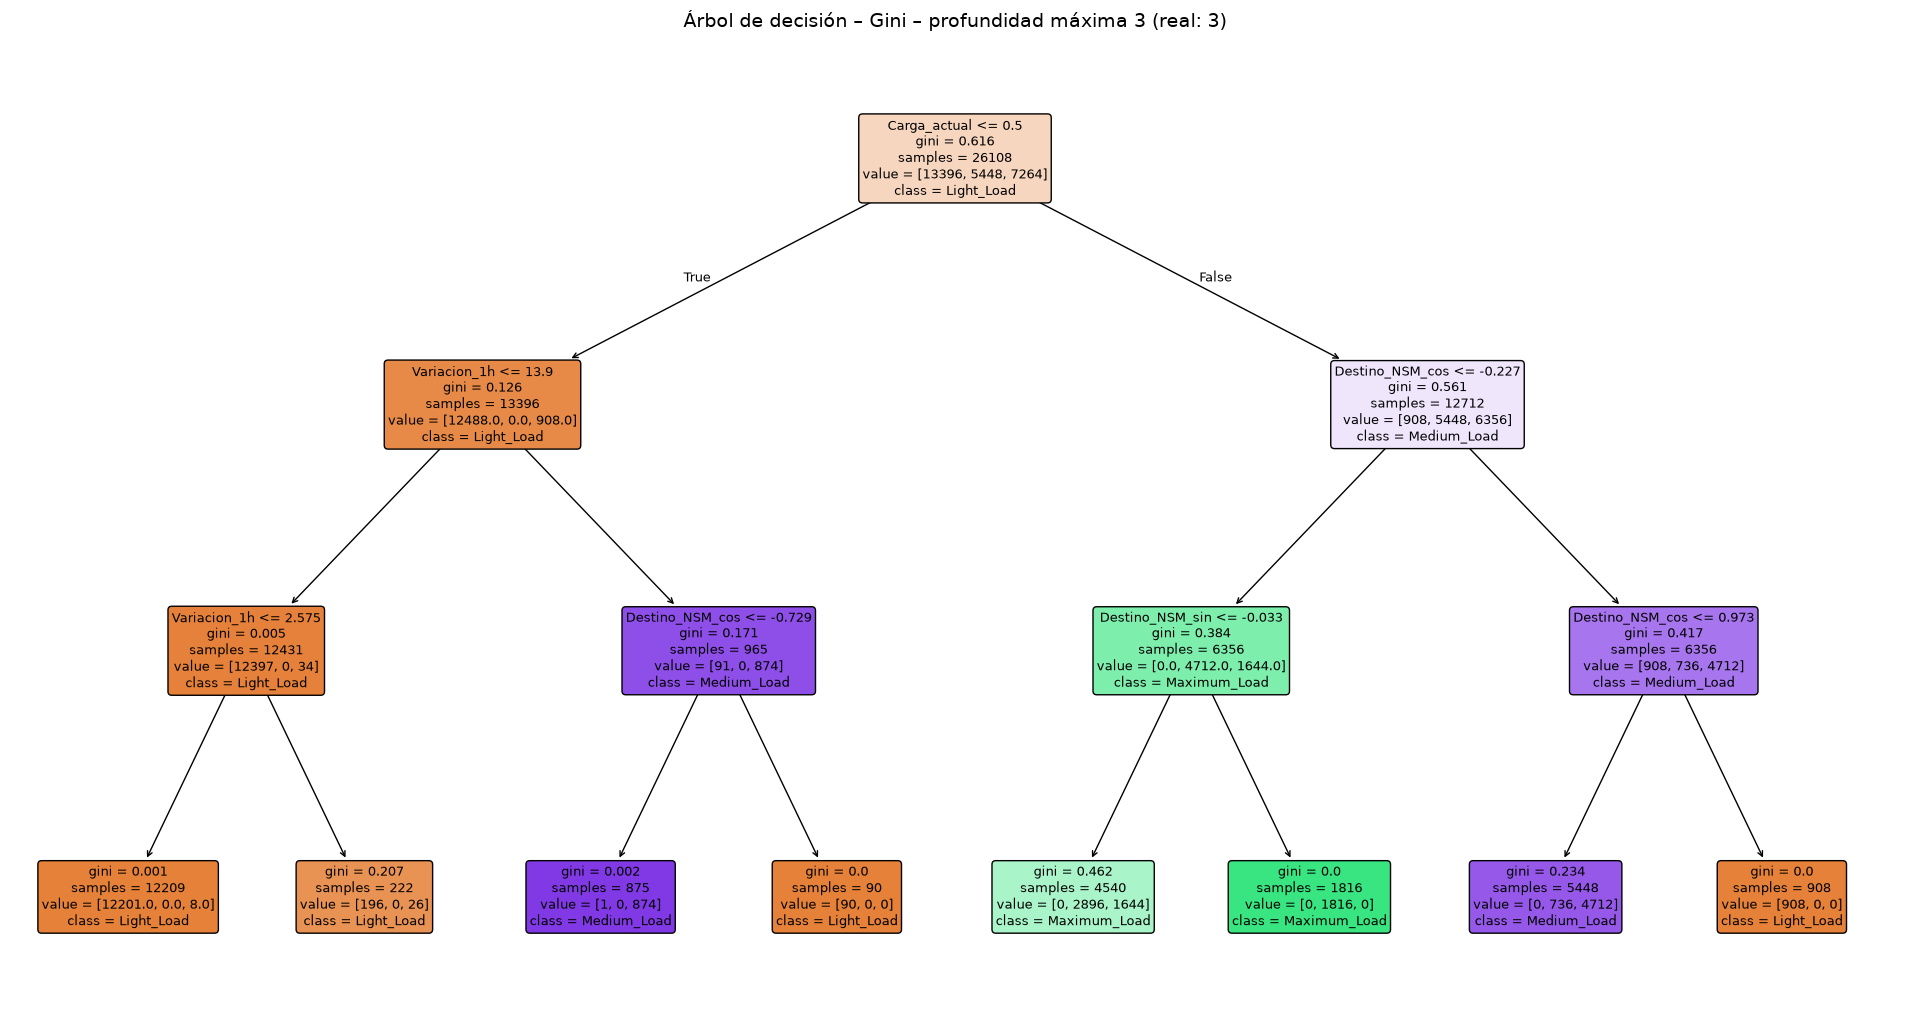

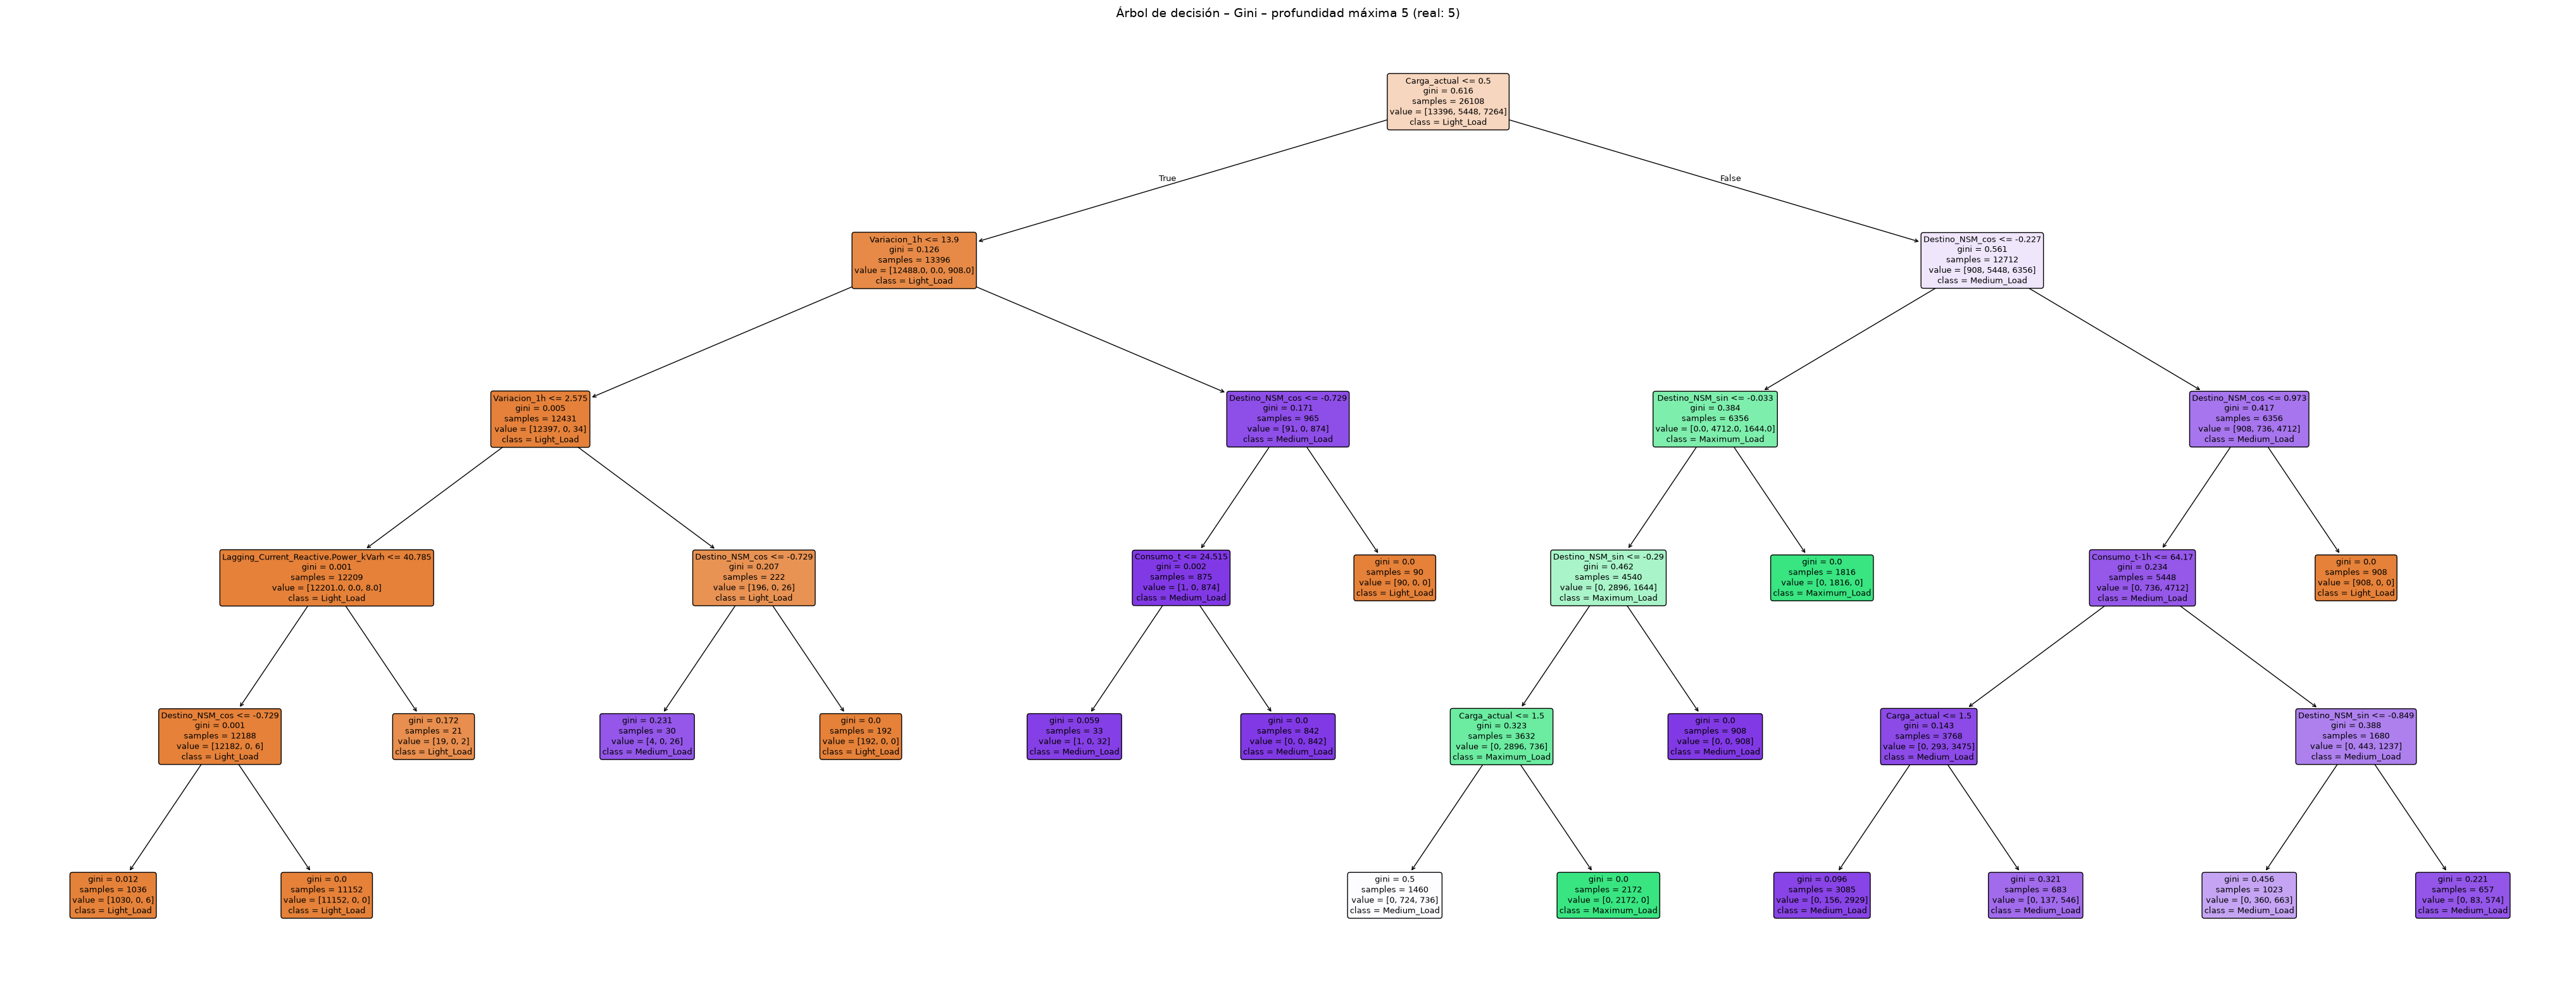

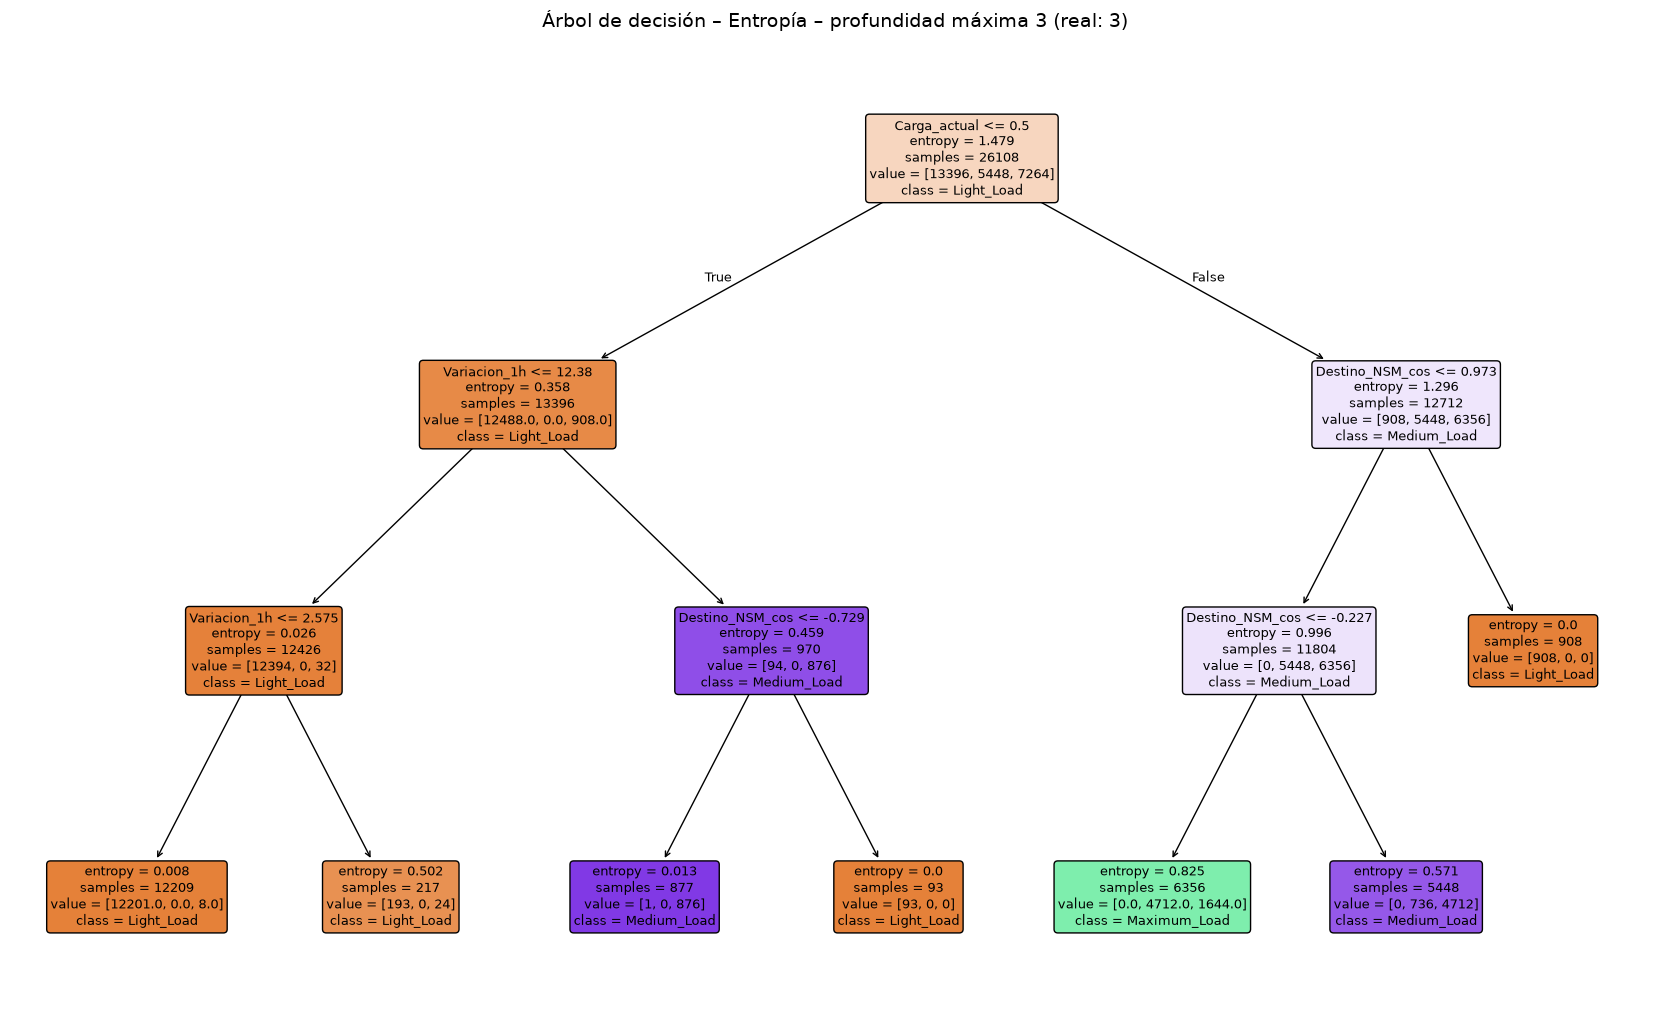

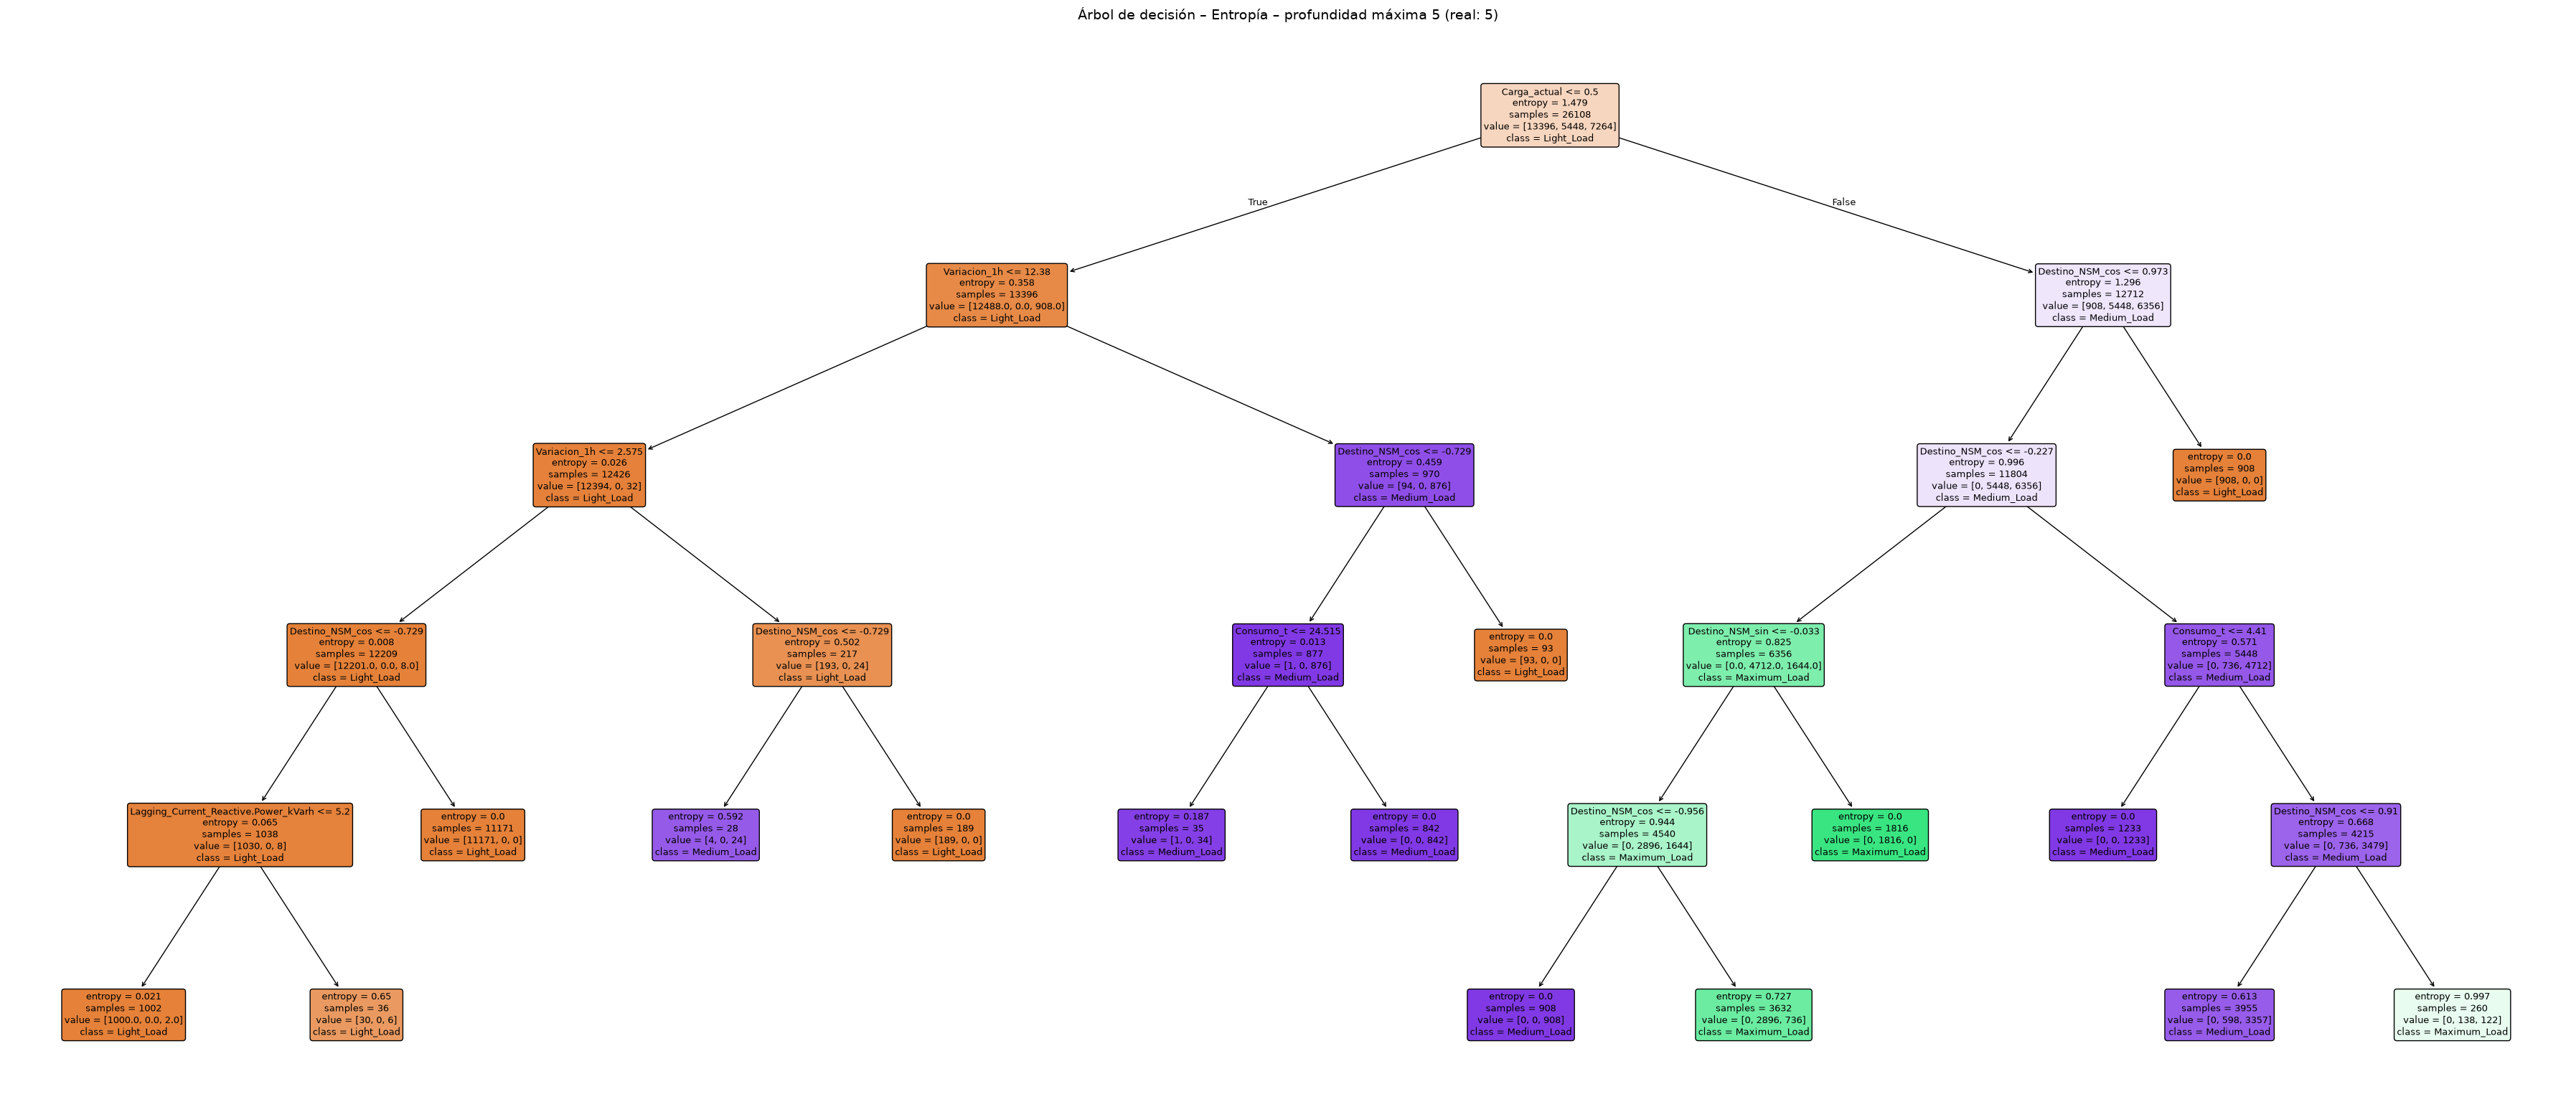

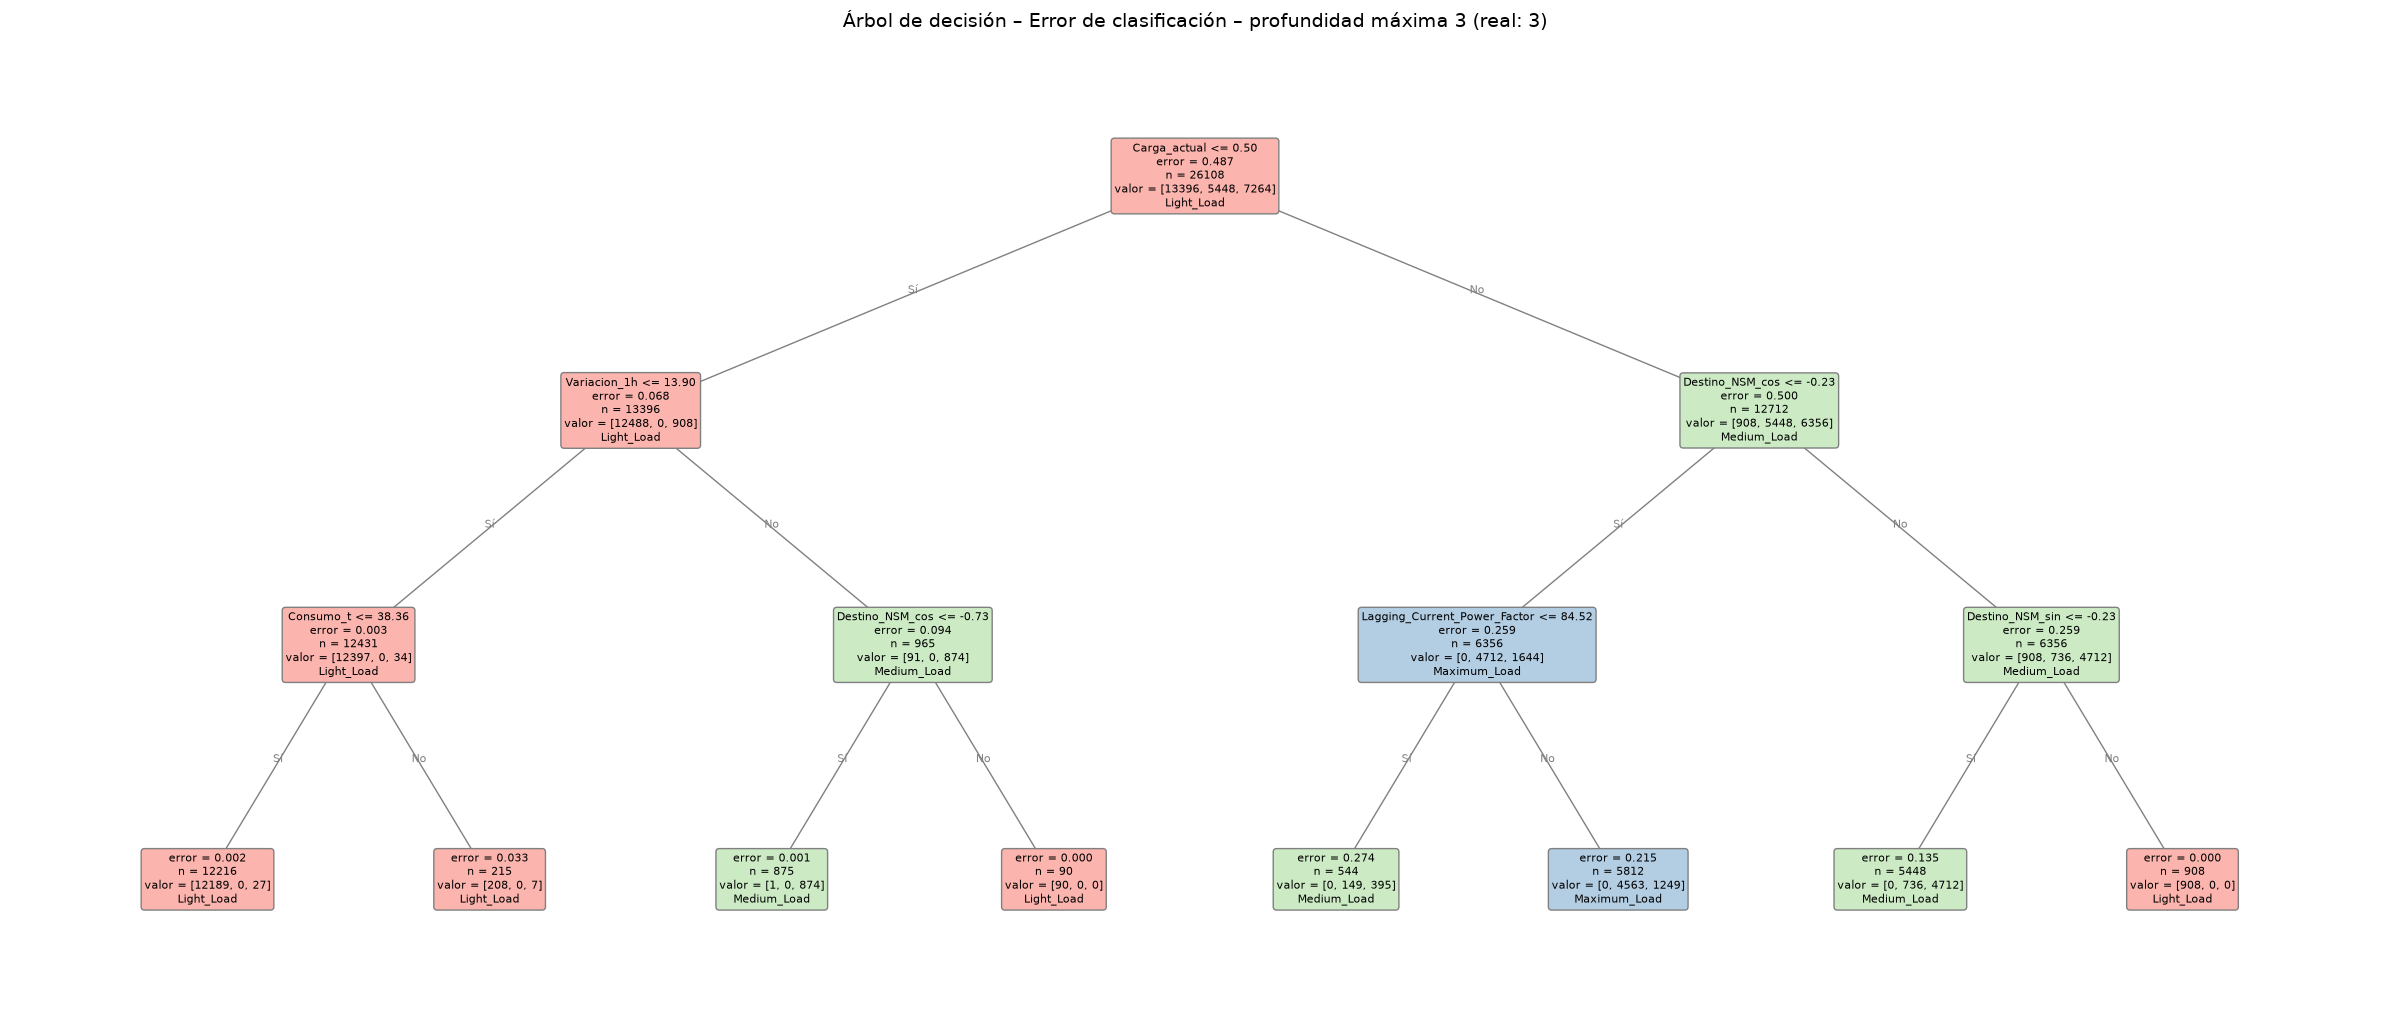

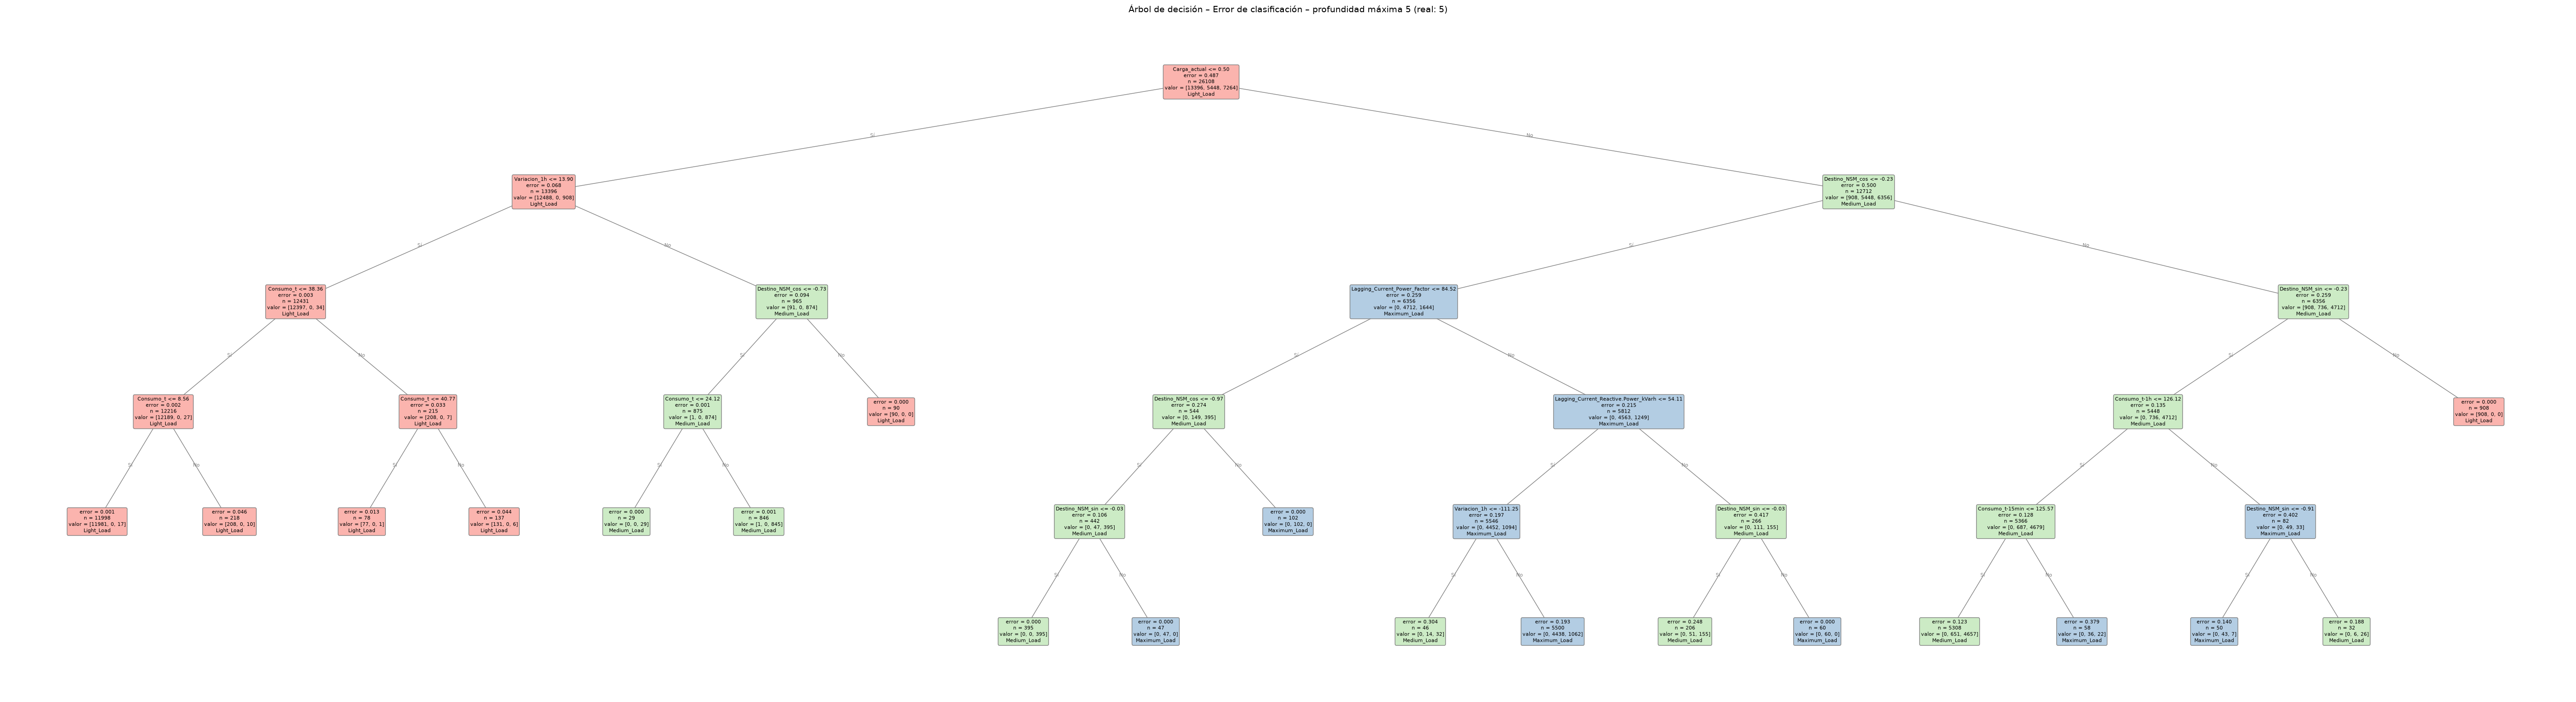

In [5]:
# Celda 5.2: gráficos de los árboles (profundidad 3 y 5)
_ = ad.graficar_arboles(modelos_arb, list(X_tr.columns))

**Cómo leer los gráficos.** El árbol se recorre de arriba hacia abajo. Cada recuadro (nodo) muestra:

- la **pregunta** que se hace (por ejemplo, `Consumo_t <= 21.35`): si se cumple, se sigue por la rama **izquierda**; si no, por la **derecha**;
- la **impureza** del grupo según el criterio usado (mientras más cercana a 0, más homogéneo);
- cuántas mediciones llegan a ese nodo y cuántas hay de cada clase;
- la **clase predominante**.

El **color** indica la clase predominante (según la leyenda) y su **intensidad**, la pureza del grupo. Los recuadros del último nivel son las **hojas**, las respuestas finales.

**Qué observar.**

- **La pregunta de la raíz** es la que mejor separa los datos: indica cuál es la variable más informativa para pronosticar.
- Si las primeras preguntas son sobre el **consumo previo** y las siguientes sobre la **hora del destino**, el árbol combina el estado presente con el calendario.
- Los árboles de profundidad 3 pueden leerse completos; los de profundidad 5 son más precisos pero difíciles de leer en una imagen, por lo que conviene apoyarse en las reglas escritas (celda 5.4).

**Resultados.** Los seis árboles hacen la misma pregunta en la raíz: **`Carga_actual ≤ 0,5`**, es decir, *¿la planta está hoy en carga liviana o no?* En el segundo nivel, la rama liviana pregunta por **`Variacion_1h`** (umbral cercano a 13,9 kWh: ¿el consumo subió mucho en la última hora?) y la rama no liviana, por **`Destino_NSM_cos`** (la hora del instante pronosticado). Después aparecen `Destino_NSM_sin`, `Consumo_t`, la reactiva inductiva y el factor de potencia. Los árboles combinan, como se esperaba, el **estado presente** con el **calendario del destino**.


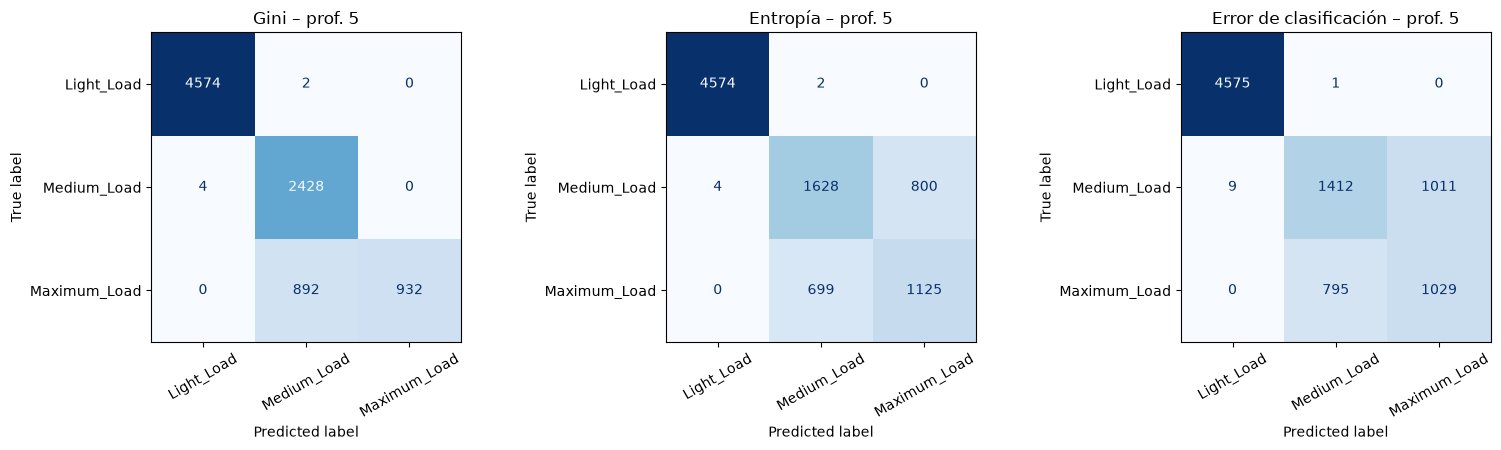

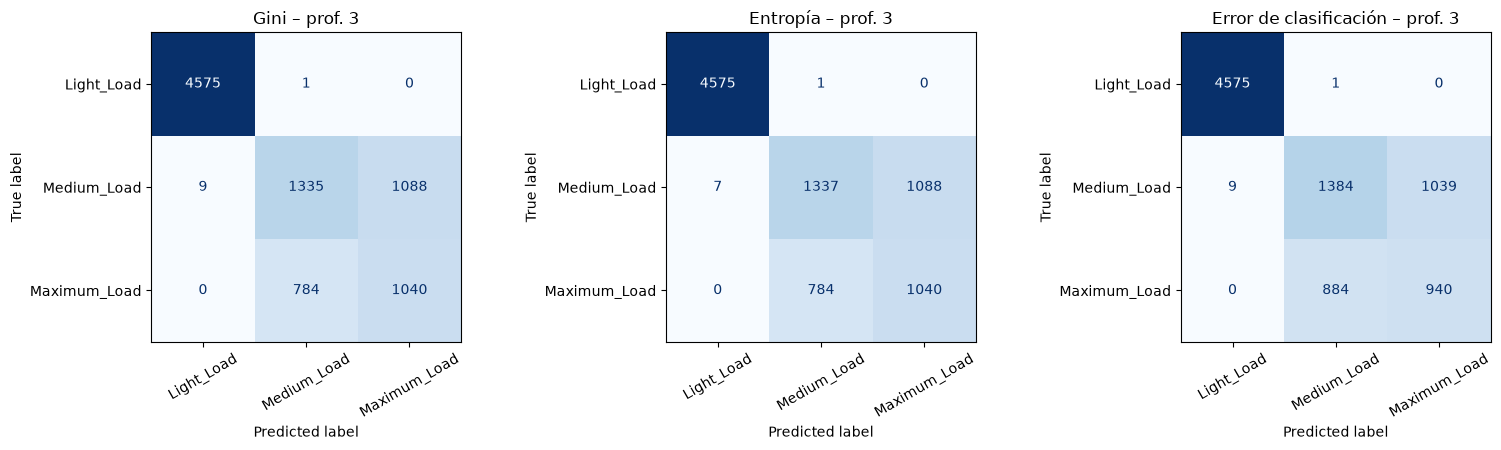

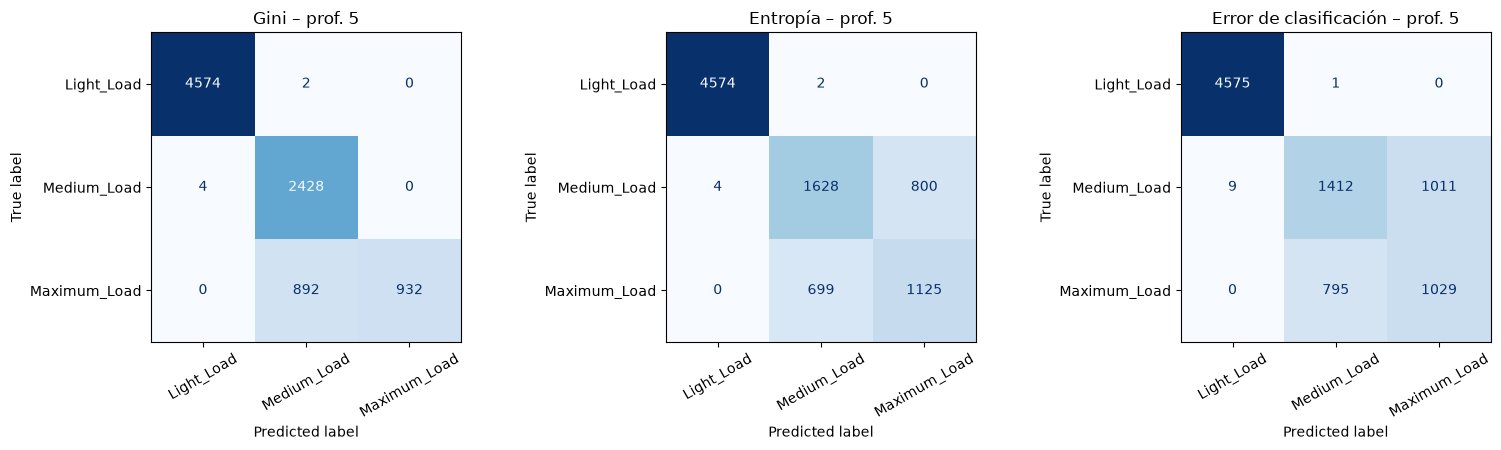

In [6]:
# Celda 5.3: matrices de confusión (profundidad 3 y 5)
ad.graficar_matrices_confusion(preds_arb, y_te, 3, pr.ORDEN_CARGA)
ad.graficar_matrices_confusion(preds_arb, y_te, 5, pr.ORDEN_CARGA)

**Cómo leer una matriz de confusión.** Es una tabla de aciertos y errores sobre el conjunto de prueba. Las **filas** son el nivel de carga que realmente hubo y las **columnas**, el que pronosticó el modelo. La **diagonal** contiene los **aciertos**; todo lo que está fuera de ella son errores. Los tonos más oscuros señalan más casos.

**Qué observar.**

- Qué nivel se pronostica mejor y cuál peor.
- **Dónde se concentran los errores.** Lo esperable es que se confundan niveles *contiguos* (media con máxima), no los extremos.
- La celda **"Maximum real → pronosticado como Medium"** corresponde a cargas máximas que *no se alertarían*: es el error más costoso para el sistema.

**Resultados.** La **carga liviana se pronostica casi sin errores** en los seis árboles (4.574 o 4.575 de 4.576 casos) y **nunca hay saltos entre los extremos**: ninguna carga máxima se pronosticó como liviana ni al revés. Todos los errores ocurren entre carga media y máxima.

- **Profundidad 5, Gini:** la carga media se acierta casi siempre (2.428 de 2.432), pero solo **932 de 1.824** cargas máximas (51,1 %). Las otras **892** se pronostican como media, que es el error más costoso para el sistema de alertas. A cambio, no genera falsas alarmas de carga máxima.
- **Profundidad 5, entropía:** reparte los errores en ambos sentidos. Acierta 1.628 de 2.432 cargas medias (66,9 %) y 1.125 de 1.824 máximas (61,7 %), con 800 medias anunciadas como máximas y 699 máximas no detectadas.
- **Profundidad 5, error de clasificación:** acierta el 58,1 % de las medias y el 56,4 % de las máximas, con 1.011 medias anunciadas como máximas y 795 máximas no detectadas.
- **Profundidad 3:** los tres árboles confunden más de mil cargas medias como máximas (1.088 con Gini y entropía; 1.039 con error de clasificación) y dejan sin detectar entre 784 y 884 cargas máximas.

,Gini,Entropía,Error de clasificación
Consumo_t,0.0000,0.0090,0.0000
Consumo_t-15min,0.0000,0.0000,0.0013
Consumo_t-1h,0.0057,0.0000,0.0015
Consumo_t-24h,0.0000,0.0000,0.0000
Variacion_1h,0.1033,0.1246,0.0737
Carga_actual,0.5437,0.5223,0.5010
Lagging_Current_Reactive.Power_kVarh,0.0000,0.0007,0.0040
Leading_Current_Reactive_Power_kVarh,0.0000,0.0000,0.0000
Lagging_Current_Power_Factor,0.0000,0.0000,0.0226
Leading_Current_Power_Factor,0.0000,0.0000,0.0000


,Criterio,Profundidad,Accuracy_train,Accuracy_test
0,Gini,1,0.7218,0.7246
1,Gini,2,0.8693,0.7514
2,Gini,3,0.9075,0.7869
3,Gini,4,0.9431,0.8218
4,Gini,5,0.9436,0.8983
5,Gini,6,0.9679,0.9141
6,Gini,7,0.9748,0.9392
7,Gini,8,0.9848,0.9471
8,Gini,9,0.9866,0.9445
9,Gini,10,0.9877,0.9447


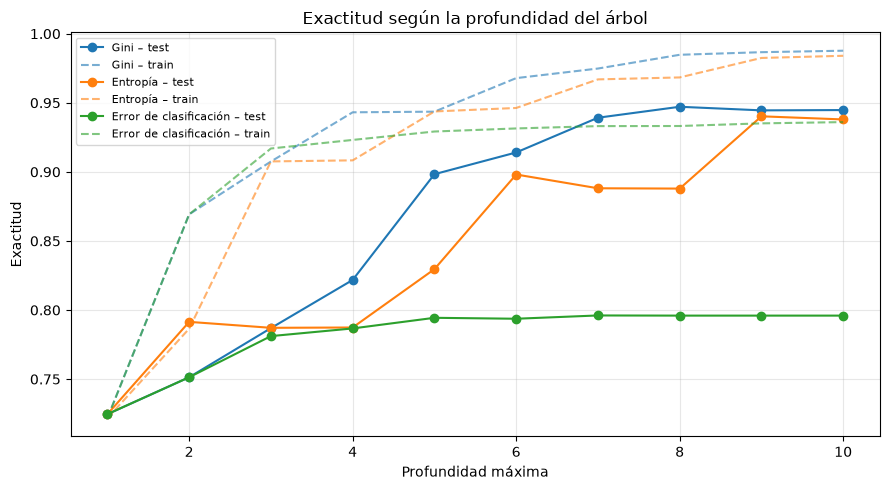

In [28]:
# Celda 5.4: reglas del árbol, importancia de variables y curva de profundidad
display(ad.tabla_importancias(modelos_arb, X_tr.columns, 5))

curva_prof = ad.curva_profundidad(X_tr, X_te, y_tr, y_te, range(1, 11))
display(curva_prof)
ad.graficar_curva_profundidad(curva_prof);

**Importancia de variables.** Indica cuánto contribuyó cada variable a reducir la impureza en los árboles de profundidad 5: una variable importante es una que el árbol usa en preguntas cercanas a la raíz o en muchos nodos.

**Curva de profundidad.** Muestra la exactitud en entrenamiento (línea punteada) y en prueba (línea continua) para profundidades de 1 a 10. La curva de **entrenamiento sube siempre** con la profundidad, porque el árbol se ajusta cada vez más a lo que ya vio. La de **prueba** mejora hasta cierto punto y luego se estabiliza o empeora: ahí comienza el **sobreajuste**. La profundidad adecuada es la que ya no mejora la prueba.

**Resultados.**

- **Reglas (Gini, prof. 3):** si hoy hay carga liviana, se pronostica liviana, salvo que el consumo suba más de 13,9 kWh y el destino sea cercano al mediodía, caso en que se pronostica media. Si hoy no hay carga liviana, el destino entre aproximadamente las 7 y las 17 h (`Destino_NSM_cos ≤ −0,23`) lleva a **carga máxima**; cerca de la medianoche (`Destino_NSM_cos > 0,97`) lleva a liviana, y en el resto del día, a media. Son reglas que el personal de la planta puede validar.
- **Variables más importantes (prof. 5):** `Carga_actual` (0,54 con Gini; 0,52 con entropía; 0,50 con error), `Destino_NSM_cos` (0,26; 0,31; 0,30), `Variacion_1h` (0,10; 0,12; 0,07) y `Destino_NSM_sin` (0,09; 0,03; 0,10). El resto aporta casi nada.
- **Curva de profundidad:** con Gini la exactitud de prueba sube hasta **la profundidad 8 (0,947)** y después se estabiliza (0,945), mientras la de entrenamiento sigue subiendo hasta 0,988. Con entropía se estabiliza hacia la profundidad 9 (0,940); con error de clasificación queda en 0,796 desde la profundidad 5. Por lo tanto, el límite de 5 niveles pedido en la tarea es **más restrictivo que lo que el problema admite**: un árbol más profundo alcanza el nivel de los ensambles.


## 6. Random Forest

Random Forest construye **muchos árboles distintos** y combina sus predicciones por votación. La diversidad se logra de dos formas: cada árbol se entrena con una **muestra aleatoria con reemplazo** de los datos, y en cada pregunta solo puede elegir entre un **subconjunto aleatorio de variables** (`max_features`). Como cada árbol se equivoca de manera distinta, al votar los errores individuales tienden a compensarse, lo que reduce el sobreajuste.

In [8]:
# Celda 6.1: elección de hiperparámetros con validación cruzada temporal (solo entrenamiento)
mejores_rf, tabla_cv_rf = rf.buscar_hiperparametros(X_tr, y_tr)
print("Mejores parámetros:", mejores_rf)
tabla_cv_rf.head(10)

Mejores parámetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 200}


,max_depth,max_features,min_samples_leaf,n_estimators,F1_macro_CV,Desv_CV,Ranking
0,None,0.5000,5,200,0.9345,0.1153,1
1,10,0.5000,5,200,0.9335,0.1150,2
2,None,0.5000,20,200,0.9330,0.1149,3
3,10,0.5000,20,200,0.9323,0.1146,4
4,None,sqrt,5,200,0.9321,0.1120,5
5,None,0.5000,50,200,0.9291,0.1148,6
6,10,0.5000,50,200,0.9285,0.1147,7
7,None,sqrt,20,200,0.9268,0.1083,8
8,10,sqrt,5,200,0.9244,0.1117,9
9,10,sqrt,20,200,0.9212,0.1075,10


**Qué muestra.** Antes del modelo final se probaron configuraciones ("hiperparámetros"): profundidad máxima de los árboles (`max_depth`), variables candidatas por pregunta (`max_features`) y tamaño mínimo de las hojas (`min_samples_leaf`). Cada una se evaluó **solo con el entrenamiento**, dividiéndolo en bloques cronológicos. `F1_macro_CV` es el desempeño promedio en esos bloques, `Desv_CV` su variabilidad y `Ranking` el orden.

**Cómo interpretarlo.** Si las mejores configuraciones tienen puntajes muy parecidos, el modelo es **poco sensible** a estos ajustes. Una desviación alta indica que el desempeño cambia según el periodo evaluado, es decir, que no todos los meses se comportan igual.

**Resultados.** La mejor configuración fue `max_depth=None`, `max_features=0,5`, `min_samples_leaf=5` y 200 árboles, con **F1 macro de validación de 0,9345**. Las mejores configuraciones son muy parecidas (la segunda obtiene 0,9335 y las cuatro primeras quedan entre 0,9323 y 0,9345), por lo que el modelo es **poco sensible** a estos ajustes; solo bajan algo las que miran pocas variables por pregunta o usan hojas grandes (0,924–0,929). La desviación entre bloques es alta (cerca de 0,115): los primeros bloques se validan habiendo entrenado con muy pocos meses y rinden bastante peor.


In [9]:
# Celda 6.2: entrenamiento y evaluación del modelo final
modelo_rf = rf.entrenar_random_forest(X_tr, y_tr, **mejores_rf)
metricas_rf, pred_rf = rf.evaluar_modelo(modelo_rf, X_tr, X_te, y_tr, y_te)
pd.DataFrame([metricas_rf])

,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,0.9975,0.9518,0.0482,0.9321,0.8761,0.8922


**Cómo interpretarlo.** Compara la exactitud en entrenamiento y en prueba. Una diferencia grande significa que el bosque **reproduce bien el pasado** pero no necesariamente generaliza. Compara además el F1 macro de prueba con el de validación de la celda 6.1: si el de prueba es bastante menor, el último trimestre es más difícil que los meses con que se validó (posible efecto estacional).

**Resultados.** Exactitud de entrenamiento **0,9975** y de prueba **0,9518** (error de 4,8 %); F1 macro de prueba **0,932**; recall de carga máxima **0,876** y precisión **0,892**. El bosque reproduce casi perfectamente el entrenamiento (brecha de 4,6 puntos con la prueba), pero generaliza bien: el F1 de prueba (0,932) es igual al de validación (0,9345), por lo que el último trimestre no resultó más difícil que los meses con que se validó.


,N_arboles,Accuracy_train,Accuracy_test,F1_macro_test
0,1,0.9918,0.9544,0.9358
1,5,0.9971,0.9534,0.9343
2,10,0.9975,0.9518,0.9321
3,25,0.9976,0.9518,0.9322
4,50,0.9977,0.9530,0.9339
5,100,0.9977,0.9515,0.9318
6,200,0.9975,0.9518,0.9321
7,300,0.9974,0.9513,0.9315


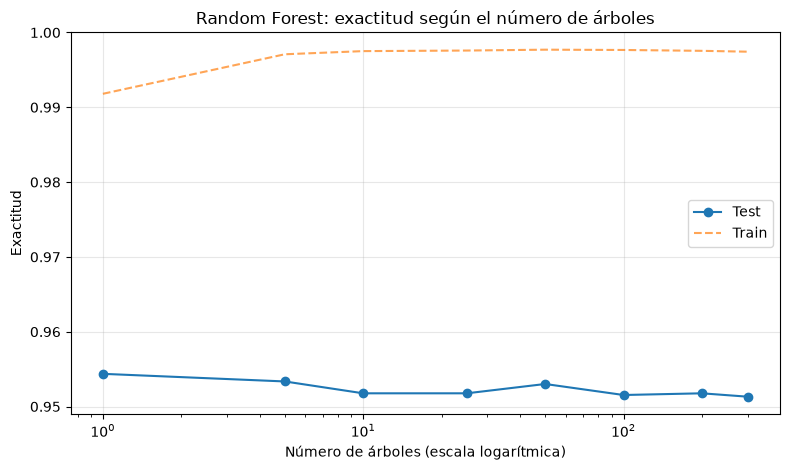

In [10]:
# Celda 6.3: efecto del número de árboles (con los mismos hiperparámetros del modelo final)
curva_rf = rf.curva_n_arboles(X_tr, X_te, y_tr, y_te,
                              max_depth=mejores_rf["max_depth"],
                              max_features=mejores_rf["max_features"],
                              min_samples_leaf=mejores_rf["min_samples_leaf"])
display(curva_rf)
rf.graficar_curva_n_arboles(curva_rf);

**Cómo leer el gráfico.** El eje horizontal (en escala logarítmica) es el número de árboles y el vertical, la exactitud. La línea punteada es el entrenamiento y la continua, la prueba.

**Cómo interpretarlo.** En Random Forest, agregar árboles no empeora el modelo, pero la mejora se **satura** rápido. Interesa ver desde qué número de árboles la curva de prueba queda plana: a partir de ahí, más árboles solo aumentan el costo computacional.

**Resultados.** La curva es **plana desde el primer árbol**: con 1 árbol la exactitud de prueba es 0,954; con 5, 0,953; con 10, 0,952; y con 300, 0,951. Agregar árboles no mejora la exactitud, y deja de aportar prácticamente desde 1 árbol. Esto se debe a que cada árbol del bosque no tiene límite de profundidad (`max_depth=None`) y ya captura la estructura del problema; el bosque sirve más por **estabilidad** que por exactitud.


,Modelo,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,"Árbol único (Gini, prof. 5)",0.9436,0.8983,0.1017,0.8399,0.5110,1.0000
1,Random Forest,0.9975,0.9518,0.0482,0.9321,0.8761,0.8922


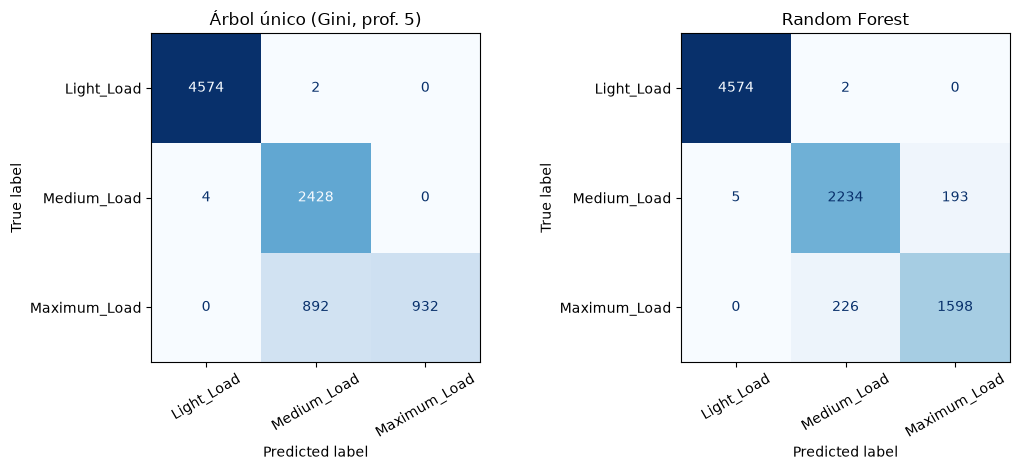

In [11]:
# Celda 6.4: bosque frente a un árbol único, y matrices de confusión
tabla_cmp_rf, modelos_cmp_rf, preds_cmp_rf = rf.comparar_bosque_vs_arbol(X_tr, X_te, y_tr, y_te, mejores_rf)
display(tabla_cmp_rf)
rf.graficar_matrices_confusion(preds_cmp_rf, y_te);

**Qué muestra.** Un árbol único (Gini, profundidad 5) y el bosque, evaluados en las mismas condiciones, con sus matrices de confusión (se leen como en la sección 5).

**Cómo interpretarlo.** Pregunta clave: **¿combinar muchos árboles mejora a uno solo?** Random Forest corrige errores debidos a la *inestabilidad* de un árbol individual; no puede corregir errores debidos a que *la información no alcanza* para distinguir dos niveles de carga. Si no mejora, el límite está en los datos y no en el modelo.

**Resultados.**

| Modelo | Exactitud | F1 macro | Recall carga máx. | Precisión carga máx. |
|---|---|---|---|---|
| Árbol único (Gini, prof. 5) | 0,898 | 0,840 | 0,511 | 1,000 |
| Random Forest | **0,952** | **0,932** | **0,876** | 0,892 |

El bosque supera al árbol en **5,4 puntos de exactitud** y en 9,2 de F1. En las matrices, las cargas máximas no detectadas bajan de **892 a 226**; a cambio aparecen 193 falsas alarmas (Medium pronosticado como Maximum), que el árbol no tenía. Se debe aclarar que parte importante de la ventaja viene de que el bosque no limita la profundidad: en la celda 5.4, un árbol Gini de profundidad 8 ya alcanza 0,947.


,Imp_impureza,Imp_permutacion,Desv_permutacion
Carga_actual,0.3245,0.3818,0.0050
Destino_NSM_sin,0.1401,0.2333,0.0027
Destino_NSM_cos,0.1960,0.2133,0.0027
Variacion_1h,0.0345,0.0037,0.0005
Leading_Current_Reactive_Power_kVarh,0.0089,0.0010,0.0002
Lagging_Current_Power_Factor,0.0351,0.0006,0.0002
Consumo_t-1h,0.0500,0.0002,0.0003
Destino_WeekStatus_bin,0.0008,-0.0005,0.0002
Leading_Current_Power_Factor,0.0040,-0.0006,0.0001
Consumo_t-24h,0.0073,-0.0009,0.0004


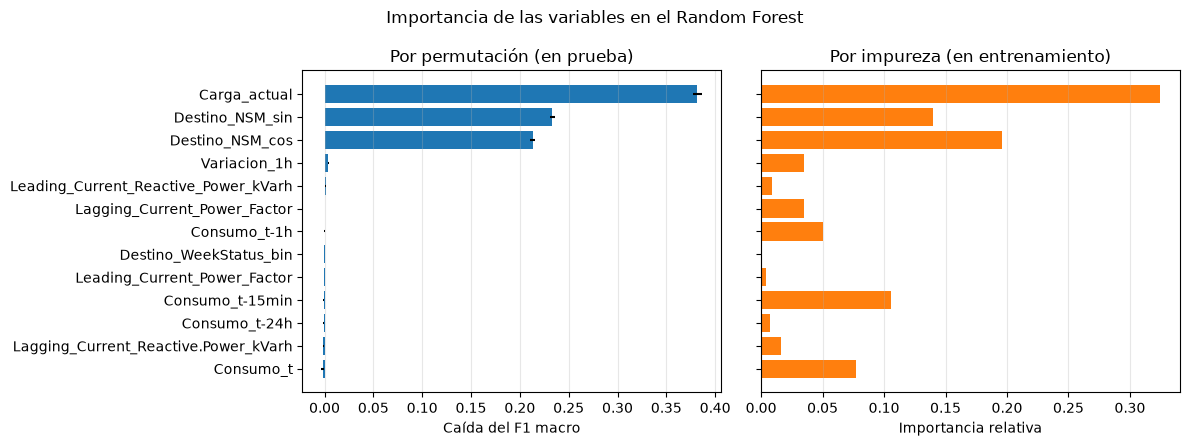

In [12]:
# Celda 6.5: importancia de las variables
imp_rf = rf.tabla_importancias(modelo_rf, X_te, y_te)
display(imp_rf)
rf.graficar_importancias(imp_rf);

**Cómo leer el gráfico.** Hay dos medidas de importancia:

- **Por permutación (izquierda):** se desordenan al azar los valores de una variable en los datos de prueba y se mide cuánto empeora el modelo. Si empeora mucho, la variable era importante. Es la medida **más confiable**, porque se calcula sobre datos no vistos.
- **Por impureza (derecha):** mide cuánto contribuyó cada variable a reducir la impureza al entrenar. Es rápida, pero tiende a sobrevalorar variables continuas y correlacionadas.

**Cómo interpretarlo.** Interesa saber si lo que más pesa es el **consumo previo** (el estado de la planta), el **calendario** (la hora y el día del destino) o las **mediciones eléctricas**. Valores levemente negativos equivalen a cero. Si una variable pesa mucho por impureza pero casi nada por permutación, el modelo la usa, pero su información ya está contenida en otras variables.

**Resultados.** Por permutación, las variables que importan son **`Carga_actual` (0,382)**, `Destino_NSM_sin` (0,233) y `Destino_NSM_cos` (0,213), es decir, el **estado actual de la planta y la hora del destino**. Todas las demás quedan bajo 0,004 (la mayor es `Variacion_1h`, con 0,0037), incluidas el consumo en sus distintos rezagos y las mediciones eléctricas.

**Discrepancia entre medidas.** Por impureza, `Consumo_t-15min` (0,106) y `Consumo_t` (0,077) parecen importantes, pero por permutación valen cero: el modelo las usa, pero su información ya está contenida en `Carga_actual`, que se define a partir del consumo.


## 7. AdaBoost

AdaBoost (*Adaptive Boosting*) entrena los árboles **en secuencia**: (1) se entrena un árbol muy simple (*aprendiz débil*); (2) se aumenta el peso de las mediciones que clasificó mal; (3) el siguiente árbol se entrena prestando más atención a esos casos difíciles; (4) el proceso se repite y, al final, cada árbol vota con un peso proporcional a su acierto. Mientras Random Forest reduce la **varianza** promediando árboles complejos, AdaBoost reduce el **sesgo** combinando árboles simples que se corrigen unos a otros.

In [13]:
# Celda 7.1: elección de hiperparámetros con validación cruzada temporal (solo entrenamiento)
mejores_ab, tabla_cv_ab = ab.buscar_hiperparametros(X_tr, y_tr)
print("Mejores parámetros:", mejores_ab)
tabla_cv_ab.head(10)

Mejores parámetros: {'max_depth': 3, 'learning_rate': 0.5, 'n_estimators': 200}


,max_depth,learning_rate,n_estimators,F1_macro_CV,Desv_CV,Ranking
0,3,0.5000,200,0.9321,0.1139,1
1,3,0.5000,50,0.9313,0.1133,2
2,3,1.0000,200,0.9301,0.1129,3
3,3,1.0000,50,0.9278,0.1122,4
4,2,0.5000,200,0.9101,0.1053,5
5,3,0.1000,200,0.8971,0.0983,6
6,2,0.1000,200,0.8918,0.1000,7
7,3,0.1000,50,0.8910,0.0993,8
8,2,0.5000,50,0.8880,0.0988,9
9,2,1.0000,50,0.8796,0.0929,10


**Qué muestra.** Igual que en Random Forest, configuraciones evaluadas solo con el entrenamiento. Aquí se varían la profundidad de cada árbol (`max_depth`), la magnitud de cada corrección (`learning_rate`) y el número de árboles (`n_estimators`).

**Cómo interpretarlo.** Una tasa de aprendizaje baja hace que el modelo aprenda más lento y necesite más árboles; una alta, que se ajuste más rápido pero con más riesgo de sobreajuste. Interesa ver qué combinación gana y si las diferencias entre las mejores son pequeñas.

**Resultados.** La mejor configuración fue `max_depth=3`, `learning_rate=0,5` y 200 árboles, con **F1 macro de validación de 0,9321**. Con 50 árboles la diferencia es mínima (0,9313). Lo que sí importa es la profundidad de los árboles base: con profundidad 2 el mejor resultado baja a 0,910, y una tasa de aprendizaje de 0,1 queda en torno a 0,89–0,90 (aprende demasiado lento para 200 árboles).


In [14]:
# Celda 7.2: entrenamiento y evaluación del modelo final
modelo_ab = ab.entrenar_adaboost(X_tr, y_tr, **mejores_ab)
metricas_ab, pred_ab = ab.evaluar_modelo(modelo_ab, X_tr, X_te, y_tr, y_te)
pd.DataFrame([metricas_ab])

,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,0.9984,0.9417,0.0583,0.9171,0.8240,0.8883


**Cómo interpretarlo.** Compara entrenamiento y prueba (la diferencia mide el sobreajuste) y compara con Random Forest: ¿cuál generaliza mejor? Revisa también el recall y la precisión de carga máxima: indican qué tan bien detecta los eventos críticos y cuántas falsas alarmas genera.

**Resultados.** Exactitud de entrenamiento **0,9984** y de prueba **0,9417**; F1 macro **0,917**; recall de carga máxima **0,824** y precisión **0,888**. Frente a Random Forest (0,952; 0,932; 0,876; 0,892) rinde **algo menos en todas las métricas** (1,0 punto de exactitud) y tiene una brecha entrenamiento–prueba un poco mayor (5,7 puntos frente a 4,6). Generaliza bien, pero no mejor que el bosque.


,N_estimadores,Accuracy_train,Accuracy_test,F1_macro_test
0,1,0.9075,0.7869,0.7039
1,10,0.9432,0.8218,0.7486
2,20,0.9671,0.9022,0.8562
3,30,0.9731,0.9136,0.8736
4,40,0.9771,0.9081,0.8675
5,50,0.9791,0.9018,0.8581
6,60,0.9799,0.9176,0.8791
7,70,0.9915,0.9349,0.9070
8,80,0.9913,0.9322,0.9031
9,90,0.9925,0.9339,0.9058


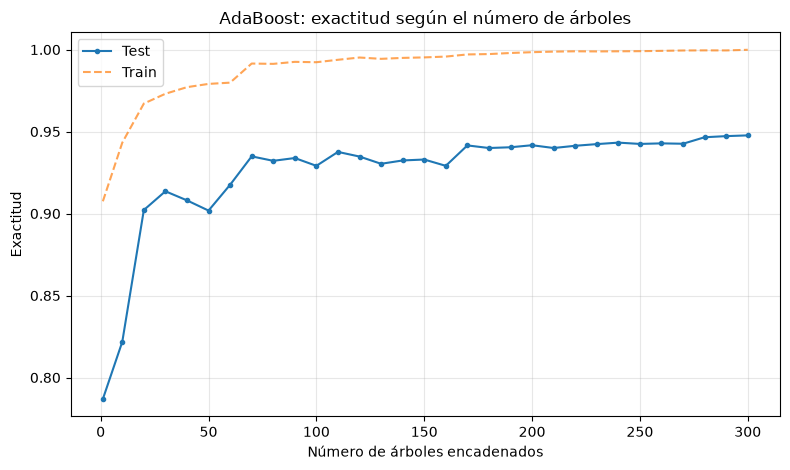

In [15]:
# Celda 7.3: efecto del número de árboles encadenados
curva_ab = ab.curva_n_estimadores(X_tr, X_te, y_tr, y_te, n_estimators=300,
                                  learning_rate=mejores_ab["learning_rate"],
                                  max_depth=mejores_ab["max_depth"])
display(curva_ab)
ab.graficar_curva_n_estimadores(curva_ab);

**Cómo leer el gráfico.** El eje horizontal indica cuántos árboles se han encadenado y el vertical, la exactitud (punteada: entrenamiento; continua: prueba).

**Qué observar.** El comportamiento característico del refuerzo: **las primeras correcciones aportan casi toda la mejora** y las siguientes solo afinan. Interesa ver cuántos árboles bastan y si la curva de prueba cae al agregar más (señal de sobreajuste).

**Resultados.** Exactitud de prueba de **0,787 con 1 árbol**, **0,822 con 10**, 0,902 con 20 y 0,935 con 70 árboles. Desde ahí fluctúa entre 0,93 y 0,95 y alcanza **0,948 con 300**. La mejora se concentra en los primeros 70 árboles; después solo afina. La curva de prueba **no cae** al agregar más árboles, de modo que no se observa un sobreajuste evidente.


,Modelo,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,Árbol pequeño solo (prof. 3),0.9075,0.7869,0.2131,0.7039,0.5702,0.4887
1,AdaBoost,0.9984,0.9417,0.0583,0.9171,0.8240,0.8883


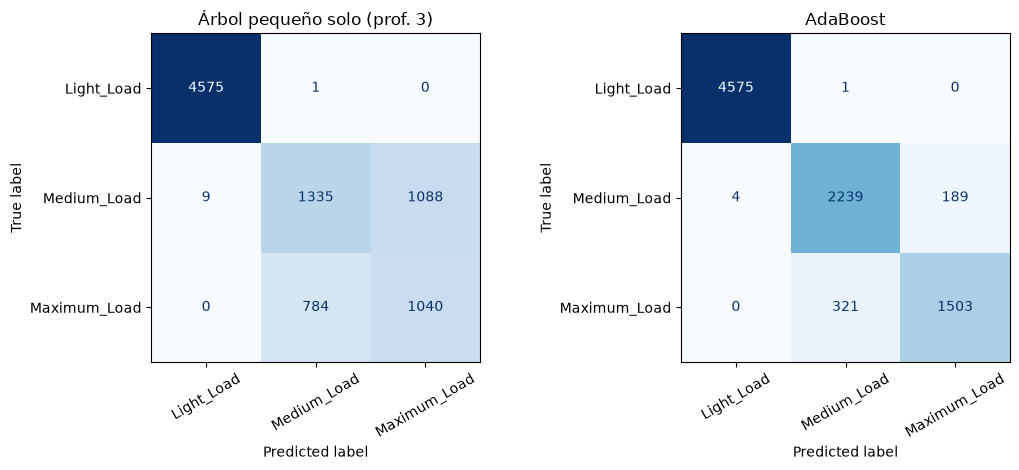

In [16]:
# Celda 7.4: un árbol pequeño aislado frente a AdaBoost, y matrices de confusión
tabla_cmp_ab, modelos_cmp_ab, preds_cmp_ab = ab.comparar_base_vs_refuerzo(X_tr, X_te, y_tr, y_te, mejores_ab)
display(tabla_cmp_ab)
ab.graficar_matrices_confusion(preds_cmp_ab, y_te);

**Qué muestra.** Un árbol pequeño solo (el mismo tipo que usa AdaBoost como base) frente al conjunto encadenado, con sus matrices de confusión.

**Cómo interpretarlo.** Esta comparación demuestra directamente **el aporte del refuerzo**: ¿cuánto mejora un modelo débil al encadenar muchos? Atención al recall de carga máxima del árbol pequeño: si es alto pero su precisión es baja, significa que **anuncia carga máxima con demasiada frecuencia** y "detecta" muchos eventos a costa de falsas alarmas, lo que lo haría inútil como sistema de alertas.

**Resultados.**

| Modelo | Exactitud | F1 macro | Recall carga máx. | Precisión carga máx. |
|---|---|---|---|---|
| Árbol pequeño solo (prof. 3) | 0,787 | 0,704 | 0,570 | 0,489 |
| AdaBoost | **0,942** | **0,917** | **0,824** | **0,888** |

El refuerzo mejora **15,5 puntos de exactitud y 21,3 de F1**. Además, en este caso **sube a la vez el recall (0,570 → 0,824) y la precisión (0,489 → 0,888)**: el árbol pequeño anunciaba carga máxima con muchas falsas alarmas y el conjunto encadenado corrige tanto lo que dejaba pasar como lo que alertaba de más.


,Imp_impureza,Imp_permutacion,Desv_permutacion
Carga_actual,0.3124,0.4634,0.0041
Destino_NSM_cos,0.2389,0.1714,0.0018
Destino_NSM_sin,0.1304,0.1620,0.0035
Consumo_t,0.0509,0.0112,0.0007
Consumo_t-1h,0.0356,0.0067,0.0007
Consumo_t-24h,0.0400,0.0064,0.0005
Leading_Current_Reactive_Power_kVarh,0.0455,0.0058,0.0006
Lagging_Current_Power_Factor,0.0288,0.0039,0.0013
Leading_Current_Power_Factor,0.0415,0.0008,0.0006
Variacion_1h,0.0261,-0.0007,0.0005


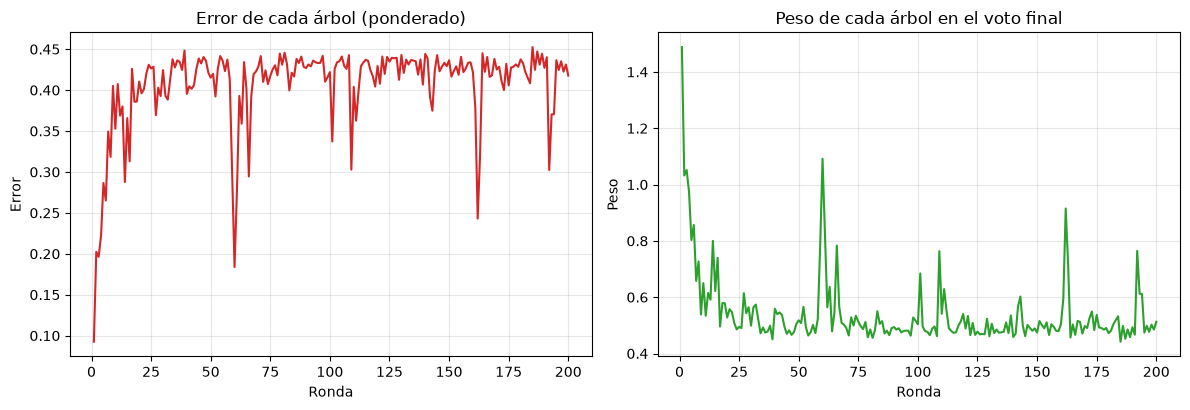

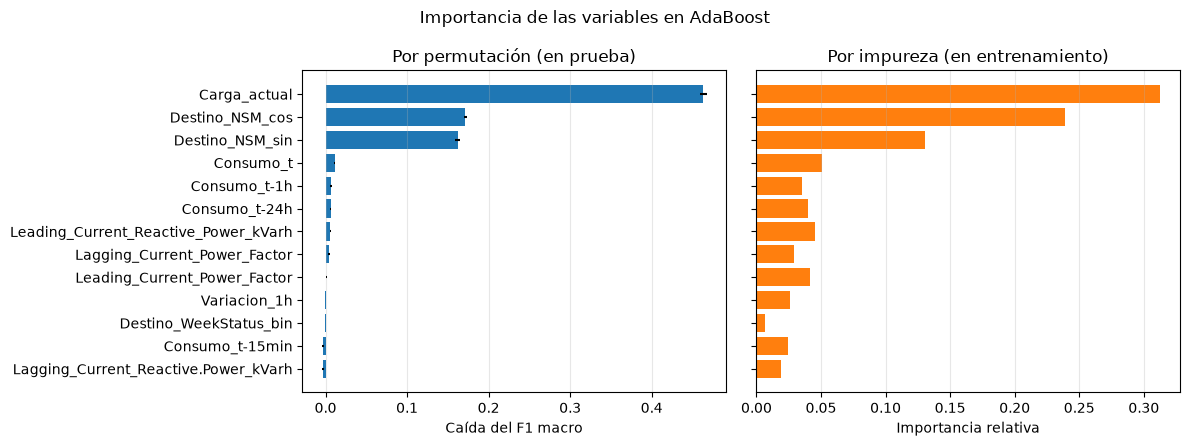

In [17]:
# Celda 7.5: funcionamiento interno del refuerzo e importancia de variables
ab.graficar_rondas(modelo_ab);
imp_ab = ab.tabla_importancias(modelo_ab, X_te, y_te)
display(imp_ab)
ab.graficar_importancias(imp_ab);

**Gráficos de rondas.** Muestran el mecanismo interno de AdaBoost:

- **Error de cada árbol (ponderado):** suele crecer con las rondas y acercarse a 0,5. No es una falla: a medida que avanza el proceso, cada nuevo árbol se entrena sobre los casos **más difíciles**, que los anteriores no lograron resolver.
- **Peso de cada árbol en el voto final:** los primeros árboles, más certeros, reciben pesos altos; los últimos, pesos bajos. El modelo **confía más en los árboles que resolvieron los casos generales**.

**Importancia de variables.** Se lee igual que en Random Forest (por permutación). Interesa comparar si ambos métodos, de lógicas distintas, coinciden en las variables más importantes: si es así, la conclusión es más sólida.

**Resultados.** Por permutación, las variables más importantes en AdaBoost son **`Carga_actual` (0,463)**, `Destino_NSM_cos` (0,168) y `Destino_NSM_sin` (0,167); `Consumo_t` (0,011) y el resto aportan muy poco. **Coincide con Random Forest**: las mismas tres variables encabezan la lista (cambia el orden entre seno y coseno), lo que da más solidez a la conclusión de que el pronóstico se apoya en el estado actual y en la hora del destino.


## 8. Redes bayesianas

### 8.1 Concepto

Una red bayesiana es un **grafo dirigido sin ciclos** en que cada nodo es una variable y cada flecha $A \rightarrow B$ indica que $A$ influye directamente en $B$. Cada nodo tiene una **tabla de probabilidad condicional** que indica la probabilidad de cada valor del nodo dados los valores de sus padres. La probabilidad conjunta se obtiene como:

$$P(X_1,\dots,X_n)=\prod_{i=1}^{n} P\big(X_i \mid \text{padres}(X_i)\big)$$

Para pronosticar, la red calcula $P(\text{Carga\_futura}\mid\text{evidencia})$ y elige el nivel más probable. A diferencia de los modelos anteriores, **entrega probabilidades explícitas** y permite consultas con información parcial.

> **Nota de implementación:** la red se implementó con `numpy` y `pandas` en `src/modelos_aprendizaje/redes_bayesianas.py` (aprendizaje de estructura, tablas con suavizado de Laplace e inferencia exacta por enumeración), porque `pgmpy` no estaba disponible en el entorno de trabajo.

### 8.2 Variables de la red y por qué se incluyen

Las redes de este tipo trabajan con **variables categóricas**, por lo que las variables numéricas se **discretizan** en niveles. Los cortes se calculan con **cuantiles** del entrenamiento, de modo que cada nivel tenga una cantidad similar de observaciones.

| Nodo | Origen | Niveles | Por qué se incluye |
|---|---|---|---|
| `Carga_futura` | `Load_Type` dentro de 1 hora | Light / Medium / Maximum | Es lo que se quiere pronosticar. |
| `Franja_horaria_destino` | Hora del instante pronosticado | Madrugada (0–6 h), Mañana (6–12 h), Tarde (12–18 h), Noche (18–24 h) | La actividad de la planta sigue un ciclo diario; las franjas son fáciles de interpretar. |
| `Tipo_dia_destino` | Día del instante pronosticado | Hábil / Fin de semana | La producción difiere entre semana y fin de semana. |
| `Carga_actual` | `Load_Type` ahora | Light / Medium / Maximum | Es el punto de partida del pronóstico: la carga tiende a mantenerse. |
| `Consumo_actual` | Consumo en t | Bajo / Medio / Alto | Estado presente de la planta, con más detalle que la etiqueta. |
| `Consumo_hace_1h` | Consumo en t − 1 h | Bajo / Medio / Alto | Permite ver de dónde viene el consumo. |
| `Consumo_hace_24h` | Consumo en t − 24 h | Bajo / Medio / Alto | Captura el ciclo diario: qué ocurrió a esta hora ayer. |
| `Variacion_1h` | Consumo actual − consumo hace 1 h | Cae / Estable / Sube | Resume la **tendencia**: no es lo mismo estar en carga media subiendo que bajando. |
| `Reactiva_inductiva` | Energía reactiva inductiva en t | Bajo / Medio / Alto | Refleja cuánta maquinaria pesada está operando. |
| `FP_inductivo` | Factor de potencia inductivo en t | Bajo / Medio / Alto | Resume la eficiencia eléctrica del régimen actual. |

Las variables capacitivas (reactiva y factor de potencia) se omiten de la red para mantenerla legible y con un número manejable de combinaciones; sí se usan en los demás modelos.

### 8.3 Estructuras comparadas

1. **Naive Bayes:** todas las variables dependen únicamente de `Carga_futura`, y se supone que son independientes entre sí una vez conocida la carga. Es la estructura más simple y sirve de línea base entre las redes.
2. **Experta:** diseñada con conocimiento del dominio. El calendario del destino, la carga actual, la tendencia y el consumo de hace 24 h **influyen en la carga futura**. El consumo actual determina la carga actual (la etiqueta se define a partir del consumo) y, junto con el de hace 1 h, la variación. Las mediciones eléctricas son un *efecto* de la carga actual.
3. **Aprendida (BIC):** la estructura se obtiene de los datos con una búsqueda *Hill Climbing* que maximiza el criterio **BIC** (premia el buen ajuste y penaliza la complejidad). Se imponen reglas de sentido común: **el calendario no puede ser causado por ninguna variable** y **la carga futura no puede causar lo que ocurre ahora**. Se permiten hasta 4 padres por nodo.

In [18]:
# Celda 8.1: verificación de la hora y del tipo de día del destino
display(pd.DataFrame({"hora_destino_derivada": rb.hora_del_dia(X_tr),
                      "hora_destino_real": info["fecha_objetivo_tr"].dt.hour
                                           + info["fecha_objetivo_tr"].dt.minute / 60}).head())
pd.crosstab(X_tr["Destino_WeekStatus_bin"], info["fecha_objetivo_tr"].dt.day_name())

,hora_destino_derivada,hora_destino_real
2018-01-02 00:00:00,1.0000,1.0000
2018-01-02 00:15:00,1.2500,1.2500
2018-01-02 00:30:00,1.5000,1.5000
2018-01-02 00:45:00,1.7500,1.7500
2018-01-02 01:00:00,2.0000,2.0000


fecha_objetivo,Friday,Monday,Saturday,Sunday,Thursday,Tuesday,Wednesday
Destino_WeekStatus_bin,,,,,,,
0,3744,3648,0,0,3744,3740,3744
1,0,0,3744,3744,0,0,0


**Qué muestra.** Dos verificaciones previas a la discretización:

1. La hora reconstruida a partir del seno y el coseno (`hora_destino_derivada`) debe **coincidir** con la hora real del instante pronosticado: así se garantiza que las franjas horarias se asignan correctamente.
2. La tabla cruzada debe mostrar que `Destino_WeekStatus_bin = 1` aparece **solo** en sábado y domingo, y `0` de lunes a viernes.

Estas verificaciones evitan que un error de codificación invierta el significado de las variables.

**Resultados.** Ambas verificaciones se cumplen. La hora derivada coincide exactamente con la real (por ejemplo, 1,00; 1,25; 1,50…), y `Destino_WeekStatus_bin = 1` aparece solo en sábado y domingo (3.744 casos cada uno), mientras que `0` aparece solo de lunes a viernes.


In [19]:
# Celda 8.2: entrenamiento y comparación de las tres estructuras
tabla_rb, redes, preds_rb = rb.comparar_estructuras(X_tr, X_te, y_tr, y_te)
tabla_rb

,Estructura,N_flechas,N_parametros,BIC_train,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,Naive Bayes,9,56,-213536.8000,0.8269,0.7853,0.2147,0.7138,0.5746,0.5396
1,Experta,10,478,-227805.7000,0.8713,0.8218,0.1782,0.7705,0.6826,0.6418
2,Aprendida (BIC),25,638,-163947.9000,0.8972,0.8434,0.1566,0.7798,0.6075,0.6357


**Cómo leer la tabla.** `N_flechas` y `N_parametros` miden la complejidad de la red (relaciones y probabilidades a estimar). `BIC_train` evalúa el equilibrio entre ajuste y complejidad: **mientras menos negativo, mejor**. Las demás columnas son las métricas de siempre.

**Qué comparar.**

- Cómo se ordenan las tres estructuras en BIC y en desempeño de prueba. Naive Bayes supone independencia entre las variables, lo que en una planta no se cumple (la reactiva y el factor de potencia están físicamente ligados, y el consumo actual y el de hace 15 minutos son casi iguales).
- Si la estructura aprendida mejora a la experta, es decir, si los datos descubrieron relaciones que el diseño manual no contempló.
- Cómo se comparan las redes con la persistencia: al discretizar, se pierde información fina, por lo que las redes suelen quedar por debajo de los árboles.

**Resultados.**

| Estructura | Flechas | Parámetros | BIC (entrenamiento) | Exactitud (prueba) | F1 macro | Recall carga máx. | Precisión carga máx. |
|---|---|---|---|---|---|---|---|
| Naive Bayes | 9 | 56 | −213.537 | 0,785 | 0,714 | 0,575 | 0,540 |
| Experta | 10 | 478 | −227.806 | 0,822 | 0,771 | 0,683 | 0,642 |
| **Aprendida (BIC)** | 25 | 638 | **−163.948** | **0,843** | **0,780** | 0,607 | 0,636 |

La estructura **aprendida es la mejor** tanto en BIC como en exactitud y F1 de prueba; la experta rinde mejor que Naive Bayes en prueba, pero tiene el peor BIC. La aprendida supera a la persistencia por **7,2 puntos** de exactitud (0,843 frente a 0,771) y el F1 sube de 0,706 a 0,780; Naive Bayes solo por 1,4. Aun así, queda por debajo de los árboles y los ensambles, como era esperable por la pérdida de información al discretizar.


In [20]:
# Celda 8.3: cortes de la discretización y flechas de la red aprendida
red = redes["Aprendida (BIC)"]
display(rb.tabla_cortes(red))
rb.tabla_arcos(red)

,Variable,Origen,Niveles
0,Franja_horaria_destino,Destino_NSM_sin / Destino_NSM_cos,Madrugada 0-6 h | Mañana 6-12 h | Tarde 12-18 ...
1,Tipo_dia_destino,Destino_WeekStatus_bin,Hábil | Fin de semana (valor 1)
2,Carga_actual,Carga_actual,Light_Load | Medium_Load | Maximum_Load
3,Consumo_actual,Consumo_t,Bajo: ≤ 3.42 | Medio: 3.42 a 38.05 | Alto: > 3...
4,Consumo_hace_1h,Consumo_t-1h,Bajo: ≤ 3.42 | Medio: 3.42 a 38.05 | Alto: > 3...
5,Consumo_hace_24h,Consumo_t-24h,Bajo: ≤ 3.46 | Medio: 3.46 a 38.05 | Alto: > 3...
6,Variacion_1h,Variacion_1h,Cae: ≤ -0.36 | Estable: -0.36 a 0.18 | Sube: >...
7,Reactiva_inductiva,Lagging_Current_Reactive.Power_kVarh,Bajo: ≤ 3.96 | Medio: 3.96 a 9.89 | Alto: > 9.89
8,FP_inductivo,Lagging_Current_Power_Factor,Bajo: ≤ 70.43 | Medio: 70.43 a 94.83 | Alto: >...


,Padre,Hijo
0,Franja_horaria_destino,Carga_futura
1,Carga_actual,Carga_futura
2,Reactiva_inductiva,Carga_futura
3,FP_inductivo,Carga_futura
4,Franja_horaria_destino,Carga_actual
5,Tipo_dia_destino,Carga_actual
6,Franja_horaria_destino,Consumo_actual
7,Tipo_dia_destino,Consumo_actual
8,Carga_actual,Consumo_actual
9,Carga_actual,Consumo_hace_1h


**Tabla de cortes.** Es el "diccionario" de la discretización: indica qué valores numéricos corresponden a cada nivel (por ejemplo, el consumo es *Alto* cuando supera cierto valor en kWh).

**Tabla de flechas.** Lista las relaciones *padre → hijo* que encontró el algoritmo. Interesa responder:

- ¿Cuáles son los **padres de `Carga_futura`**? Son las variables que, según los datos, determinan directamente el pronóstico.
- ¿Aparecen el calendario y el estado actual (carga o consumo)? ¿Aparece la tendencia?
- ¿Qué variables quedaron **sin relación** con la carga futura? Son las que, conocido el resto, no aportan información adicional.

**Resultados.** Los cortes (en entrenamiento): consumo **bajo ≤ 3,42 kWh**, medio de 3,42 a 38,05 y alto > 38,05; variación de 1 h **cae ≤ −0,36**, estable de −0,36 a 0,18 y **sube > 0,18**; reactiva inductiva ≤ 3,96 / 3,96–9,89 / > 9,89; factor de potencia ≤ 70,43 / 70,43–94,83 / > 94,83.

En la red aprendida, los **padres de `Carga_futura`** son `Franja_horaria_destino`, `Carga_actual`, `Reactiva_inductiva` y `FP_inductivo`. Quedan sin flecha directa hacia la carga futura el tipo de día, el consumo actual, el de hace 1 h y 24 h y la variación: su información llega a través de `Carga_actual`. Notar que los cortes de la variación son muy estrechos (±0,3 kWh): el salto de 13,9 kWh que usan los árboles queda todo dentro de "Sube", lo que le quita poder a esta variable en la red.


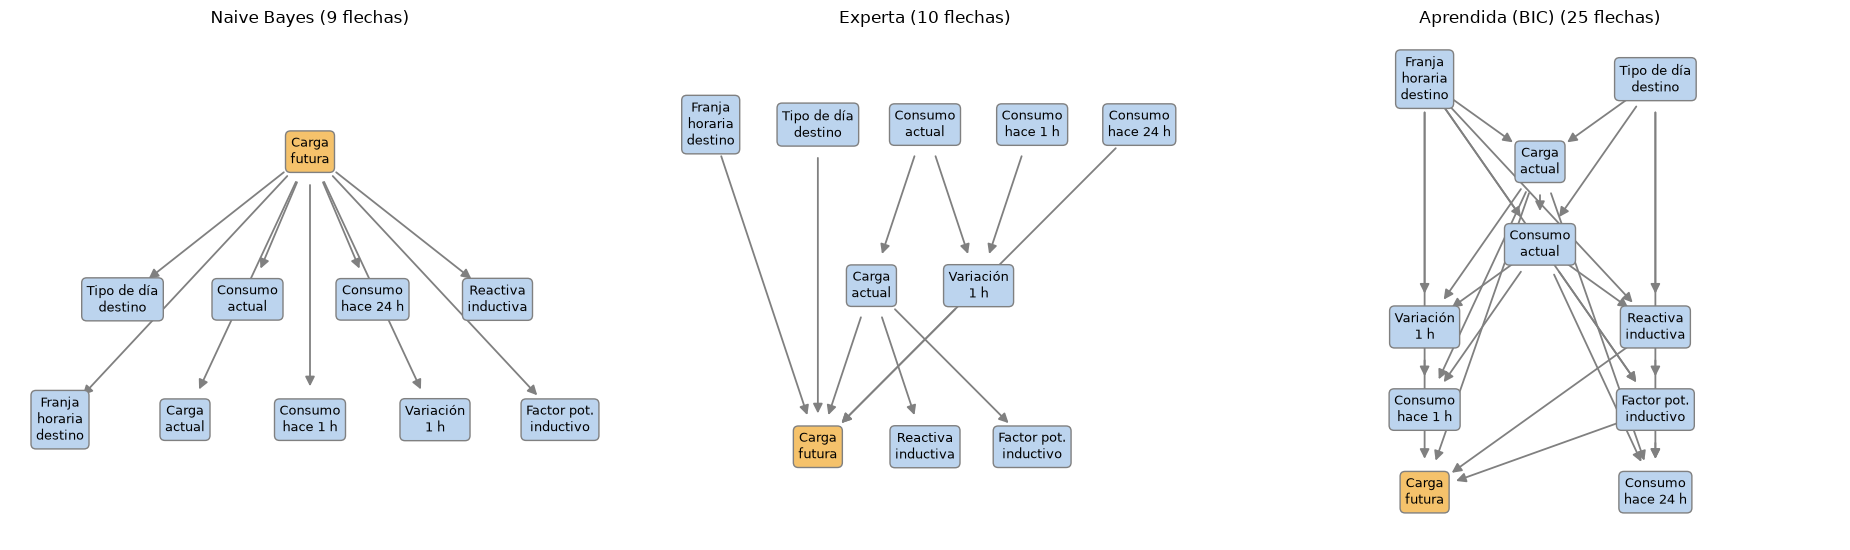

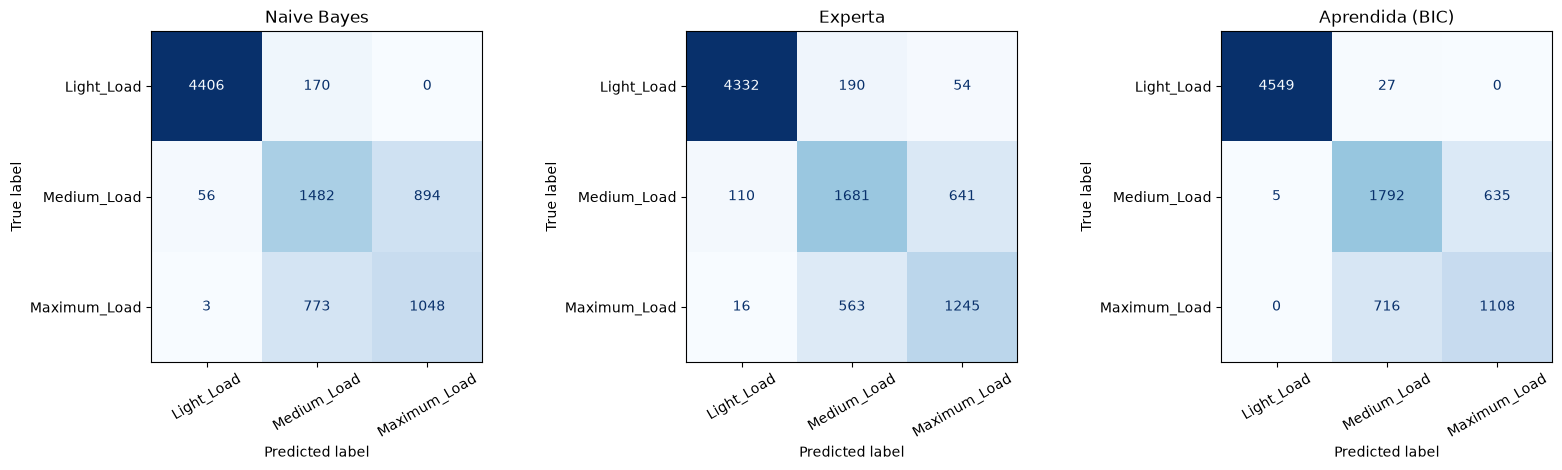

In [21]:
# Celda 8.4: grafos de las tres redes y matrices de confusión
rb.graficar_redes(redes);
rb.graficar_matrices_confusion(preds_rb, y_te);

**Cómo leer los grafos.** Cada recuadro es una variable y cada flecha, una influencia directa. El recuadro **naranja** es `Carga_futura`. Las variables se ordenan por niveles: arriba las que no tienen padres (causas) y abajo sus efectos.

- **Naive Bayes** tiene forma de estrella: todas las flechas salen de `Carga_futura`.
- **Experta** refleja la hipótesis de diseño: calendario, carga actual, tendencia y consumo de hace 24 h → carga futura.
- **Aprendida (BIC)** es la más densa: además de las relaciones con la carga futura, incluye relaciones **entre las propias variables de entrada**, que las otras estructuras ignoran.

**Matrices de confusión.** Se leen como en la sección 5. Interesa ver si el patrón de errores coincide con el de los árboles.

**Resultados.** Naive Bayes es la estrella de 9 flechas; la experta tiene 10 y las variables de entrada llegan a `Carga_futura` y a `Carga_actual`; la aprendida tiene **25 flechas**, con `Consumo_actual` y la franja horaria como nodos centrales y `Carga_futura` con cuatro padres. La aprendida incluye muchas relaciones entre variables de entrada (por ejemplo, consumo → reactiva → factor de potencia).

**Errores.** El patrón es el de los árboles: la carga liviana casi no se equivoca (4.549 de 4.576 aciertos en la red aprendida) y los errores se concentran entre media y máxima (**635** medias pronosticadas como máxima y **716** máximas pronosticadas como media). El recall de carga máxima es 0,607.


In [22]:
# Celda 8.5: consultas a la red (escenarios de alerta), con información que se va agregando
escenarios = {
    "Solo calendario (tarde, día hábil)":
        {"Franja_horaria_destino": "Tarde", "Tipo_dia_destino": "Hábil"},
    "+ la carga actual es media":
        {"Franja_horaria_destino": "Tarde", "Tipo_dia_destino": "Hábil",
         "Carga_actual": "Medium_Load"},
    "+ además el consumo viene subiendo":
        {"Franja_horaria_destino": "Tarde", "Tipo_dia_destino": "Hábil",
         "Carga_actual": "Medium_Load", "Variacion_1h": "Sube"},
    "Carga actual máxima (tarde, día hábil)":
        {"Franja_horaria_destino": "Tarde", "Tipo_dia_destino": "Hábil",
         "Carga_actual": "Maximum_Load"},
    "Madrugada, día hábil, carga actual liviana":
        {"Franja_horaria_destino": "Madrugada", "Tipo_dia_destino": "Hábil",
         "Carga_actual": "Light_Load"},
}
pd.DataFrame({nombre: red.consulta(ev) for nombre, ev in escenarios.items()}).T.round(3)

,Light_Load,Medium_Load,Maximum_Load
"Solo calendario (tarde, día hábil)",0.0520,0.3990,0.5480
+ la carga actual es media,0.0040,0.5080,0.4880
+ además el consumo viene subiendo,0.0040,0.7490,0.2470
"Carga actual máxima (tarde, día hábil)",0.0010,0.3830,0.6160
"Madrugada, día hábil, carga actual liviana",0.9970,0.0010,0.0010


**Qué muestra.** Consultas del tipo *"dada esta información, ¿qué probabilidad tiene cada nivel de carga dentro de 1 hora?"*. La red combina la evidencia con sus tablas de probabilidad. Los tres primeros escenarios **agregan información de a poco**.

**Cómo interpretarlo.** Esta tabla es la que mejor muestra la utilidad de la red para un sistema de alertas: parte de una estimación basada solo en el **calendario** y la **refina** a medida que se conoce el estado de la planta (carga actual y tendencia). Interesa ver cuánto cambia la probabilidad de carga máxima al agregar cada dato.

**Resultados.**

| Escenario | P(Light) | P(Medium) | P(Maximum) |
|---|---|---|---|
| Solo calendario (tarde, día hábil) | 0,052 | 0,399 | **0,548** |
| + carga actual media | 0,004 | 0,508 | **0,488** |
| + consumo subiendo | 0,004 | 0,749 | **0,247** |
| Carga actual máxima (tarde, día hábil) | 0,001 | 0,383 | **0,616** |
| Madrugada, día hábil, carga actual liviana | **0,997** | 0,001 | 0,001 |

Con solo el calendario de la tarde, la probabilidad de carga máxima es de 55 %. Si la carga actual es media, baja a 49 %, y si además el consumo viene subiendo, baja a **25 %**: en estos datos, un consumo creciente en carga media no anticipa la carga máxima. Es un resultado contraintuitivo, que probablemente refleja que el alza de la mañana corresponde a la puesta en marcha de la planta, y que la categoría "Sube" es muy amplia; debe tomarse con cautela. Cuando la carga actual es máxima, la probabilidad sube a 62 %, y en madrugada con carga liviana se pronostica liviana con 99,7 % de certeza.


In [23]:
# Celda 8.6: sensibilidad al número de niveles de la discretización
rb.comparar_n_bins(X_tr, X_te, y_tr, y_te, valores=(2, 3, 4, 5))

,Niveles_por_variable,N_flechas,N_parametros,Accuracy_train,Accuracy_test,Error_clasif_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load
0,2,29,340,0.8774,0.8376,0.1624,0.7807,0.6135,0.6681
1,3,25,638,0.8972,0.8434,0.1566,0.7798,0.6075,0.6357
2,4,24,1196,0.9005,0.8242,0.1758,0.7593,0.6277,0.6133
3,5,21,1036,0.8796,0.8351,0.1649,0.7808,0.7237,0.6289


**Qué muestra.** La red aprendida repetida con 2, 3, 4 y 5 niveles por variable, para ver si el resultado depende de cómo se discretiza.

**Cómo interpretarlo.** Pocos niveles pierden información; demasiados disparan el número de parámetros (`N_parametros`) y muchas combinaciones quedan con pocos datos para estimarlas, lo que empeora el desempeño. Se mantiene el valor con mejor equilibrio entre desempeño, simplicidad e interpretación.

**Resultados.**

| Niveles | Flechas | Parámetros | Exactitud (prueba) | F1 macro |
|---|---|---|---|---|
| 2 | 29 | 340 | 0,838 | 0,781 |
| **3** | 25 | 638 | **0,843** | 0,780 |
| 4 | 24 | 1.196 | 0,824 | 0,759 |
| 5 | 21 | 1.036 | 0,835 | 0,781 |

Las diferencias son pequeñas (menos de 2 puntos) y no siguen una tendencia clara, de modo que el resultado **no depende fuertemente** de la discretización. Se mantiene **3 niveles** porque tiene la mejor exactitud y son categorías fáciles de interpretar (bajo, medio, alto); con 2 niveles se obtiene casi lo mismo con la mitad de parámetros.


## 9. Comparación final de los modelos

Se comparan los cuatro modelos y las tres líneas base sobre el mismo conjunto de prueba (octubre–diciembre), con las métricas de pronóstico de la sección 2.5.

,Accuracy_train,Accuracy_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load,Acierto_cambios,Recall_subidas_Max
Modelo,,,,,,,
"Árbol (Gini, prof. 5)",0.9436,0.8983,0.8399,0.5110,1.0000,0.7505,0.3781
Random Forest,0.9975,0.9518,0.9321,0.8761,0.8922,0.8985,0.7512
AdaBoost,0.9984,0.9417,0.9171,0.8240,0.8883,0.8589,0.6505
Red bayesiana,0.8972,0.8434,0.7798,0.6075,0.6357,0.5965,0.5236
Persistencia (carga actual),0.7843,0.7713,0.7059,0.5592,0.5592,0.0000,0.0000
Calendario típico,0.8471,0.7210,0.6735,0.5702,0.4710,0.8059,0.5124
Clase mayoritaria,0.5131,0.5181,0.2275,0.0000,0.0000,0.1505,0.0000


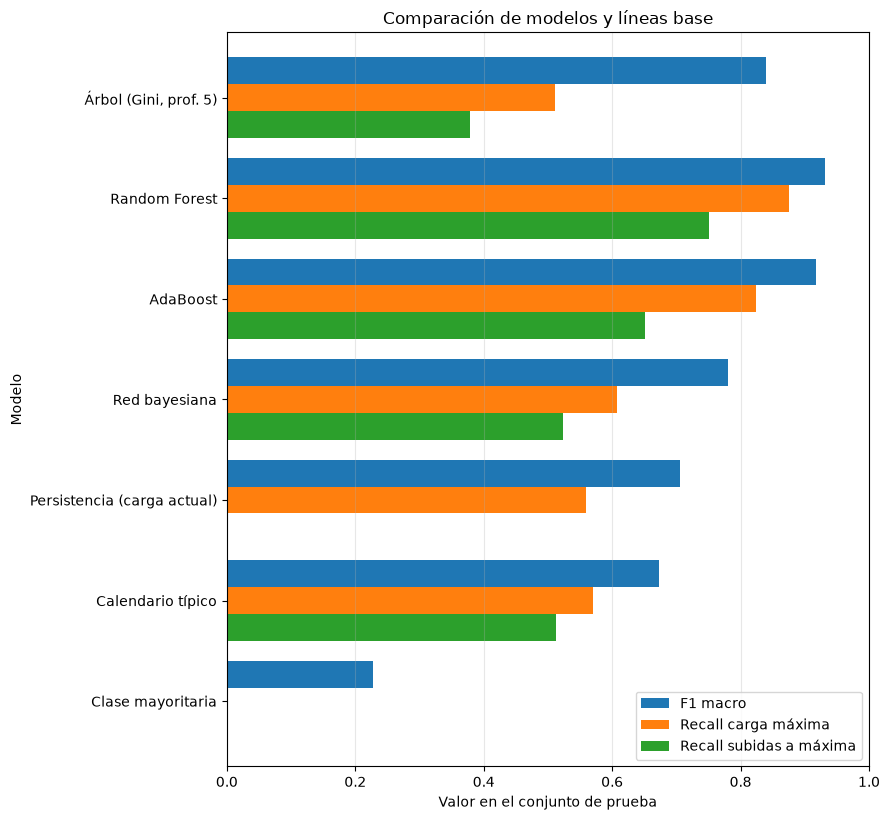

In [24]:
# Celda 9.1: tabla comparativa y gráfico
modelos_finales = {
    "Árbol (Gini, prof. 5)": modelos_arb[("gini", 5)],
    "Random Forest": modelo_rf,
    "AdaBoost": modelo_ab,
    "Red bayesiana": red,
    **bases,
}
tabla_final, preds_final = pr.comparar_modelos(modelos_finales, X_tr, X_te, y_tr, y_te)
display(tabla_final)
pr.graficar_comparacion(tabla_final);

**Cómo leer la tabla y el gráfico.** Una fila por modelo, con las mismas métricas. El gráfico muestra tres métricas por modelo: **F1 macro** (calidad general), **recall de carga máxima** (cuántos eventos críticos se detectan) y **recall de subidas a máxima** (cuántos se *anticipan*, es decir, aquellos en que ahora no hay carga máxima y dentro de 1 hora sí).

**Qué responder.**

1. ¿Cuáles modelos **superan a la persistencia** y por cuánto? Si ninguno la supera con claridad, el pronóstico no agrega valor sobre "la carga seguirá igual".
2. ¿Qué modelo anticipa más subidas a carga máxima, y a qué costo en precisión (falsas alarmas)?
3. ¿Hay diferencias reales entre los modelos de árboles, o están dentro del margen de error? Con 8.832 casos de prueba, el error de muestreo de la exactitud ronda los 0,4 puntos porcentuales: diferencias menores a eso **no son concluyentes**.
4. ¿La red bayesiana compensa su menor exactitud (si la tiene) con la información probabilística que entrega?

**Resultados.**

| Modelo | Exactitud | F1 macro | Recall carga máx. | Precisión carga máx. | Acierto en cambios | Subidas a máxima anticipadas |
|---|---|---|---|---|---|---|
| **Random Forest** | **0,952** | **0,932** | **0,876** | 0,892 | **0,899** | **0,751** |
| AdaBoost | 0,942 | 0,917 | 0,824 | 0,888 | 0,859 | 0,651 |
| Árbol (Gini, prof. 5) | 0,898 | 0,840 | 0,511 | **1,000** | 0,751 | 0,378 |
| Red bayesiana | 0,843 | 0,780 | 0,607 | 0,636 | 0,597 | 0,524 |
| Persistencia | 0,771 | 0,706 | 0,559 | 0,559 | 0 | 0 |
| Calendario típico | 0,721 | 0,674 | 0,570 | 0,471 | 0,806 | 0,512 |
| Clase mayoritaria | 0,518 | 0,228 | 0 | 0 | 0,151 | 0 |

1. **Frente a la persistencia**, los cuatro modelos la superan: Random Forest por **+18,1 puntos** de exactitud, AdaBoost por +17,0, el árbol por +12,7 y la red bayesiana por +7,2.
2. **Anticipación de subidas:** Random Forest anticipa el **75,1 %** de las subidas a máxima y AdaBoost el 65,1 %. El árbol Gini anticipa solo el 37,8 %, aunque nunca da una falsa alarma de carga máxima (precisión 1,0): es un árbol muy conservador.
3. **Entre los modelos de árboles:** Random Forest supera a AdaBoost por 1,0 punto, una diferencia superior al error de muestreo (cerca de 0,4 puntos), pero pequeña; ambos son claramente mejores que el árbol limitado a 5 niveles.
4. **Red bayesiana:** es la de menor exactitud entre los cuatro, pero es la única que entrega **probabilidades** y permite consultas con información parcial (celda 8.5), lo que compensa en parte su menor exactitud.


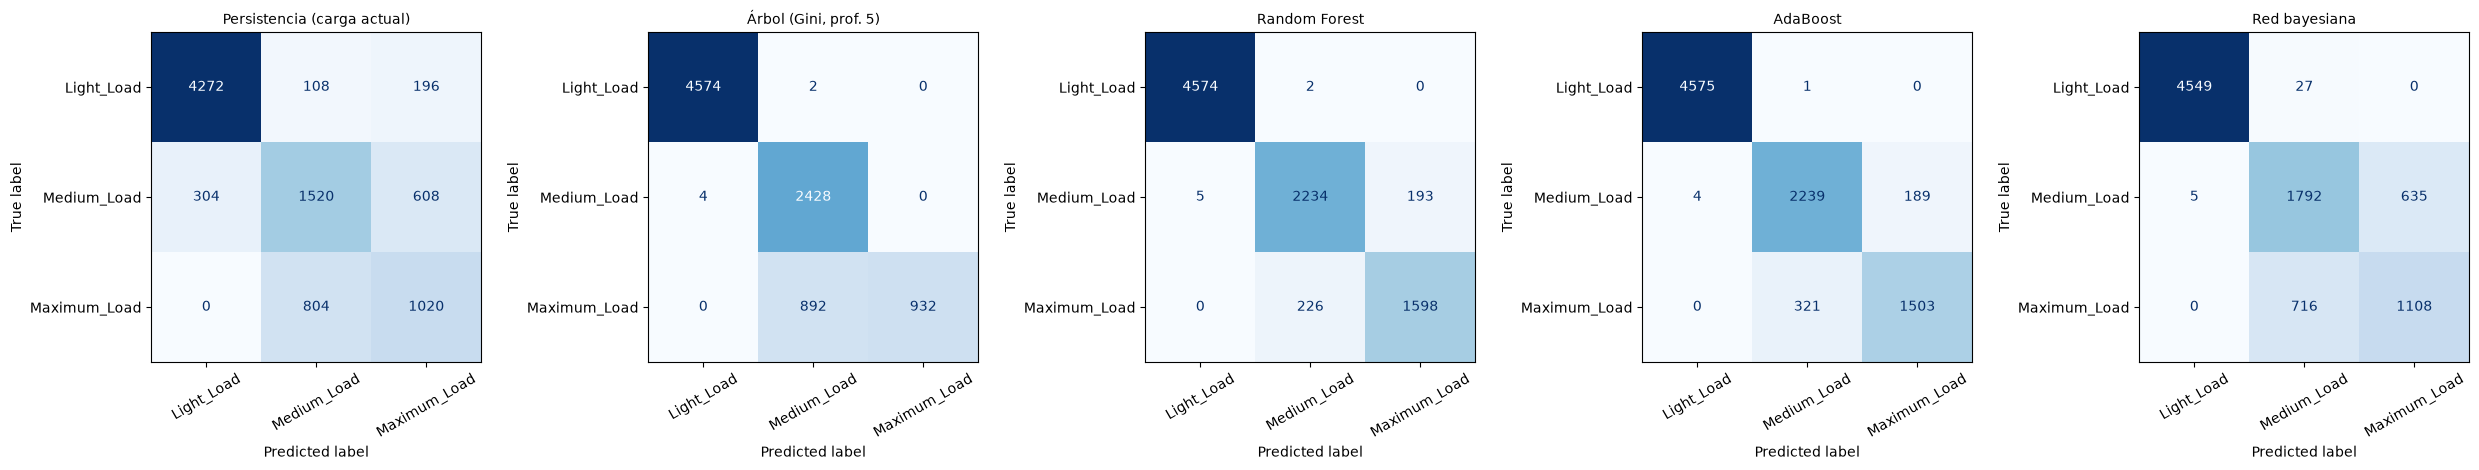

In [25]:
# Celda 9.2: matrices de confusión de los mejores modelos frente a la persistencia
elegidos = ["Persistencia (carga actual)", "Árbol (Gini, prof. 5)", "Random Forest", "AdaBoost", "Red bayesiana"]
pr.graficar_matrices_confusion({k: preds_final[k] for k in elegidos}, y_te);

**Cómo interpretarlas.** Se leen como en la sección 5. Comparadas con la matriz de la **persistencia**, muestran dónde ganan los modelos: la persistencia solo acierta en la diagonal "se mantiene" y se equivoca siempre que la carga cambia; un modelo útil debe **recuperar parte de esos cambios**. Interesa ver si los errores restantes se concentran entre media y máxima (niveles contiguos) o si hay errores gruesos entre los extremos.

**Resultados.** La persistencia acierta solo el 55,9 % de las cargas máximas (1.020 de 1.824) y deja pasar **804** sin alerta (todas las subidas). Random Forest acierta **1.598 (87,6 %)** y solo 226 se le escapan; AdaBoost acierta 1.503 (82,4 %) y la red bayesiana 1.108 (60,7 %). En carga media, la persistencia acierta 62,5 % y Random Forest 91,9 %. La carga liviana es casi perfecta en los modelos (por sobre 99 %), frente a 93,4 % de la persistencia. Los errores restantes de Random Forest se reparten entre 226 cargas máximas pronosticadas como media y 193 medias pronosticadas como máxima.


## 10. ¿Cuánto aporta el consumo previo? ¿Y si se pronostica más lejos?

Dos análisis adicionales responden a las preguntas que más importan para el proyecto.

### 10.1 Aporte de cada tipo de información

In [26]:
# Celda 10.1: mismo modelo (Random Forest) con distintos grupos de variables
ablacion = pr.ablacion_grupos(X_tr, X_te, y_tr, y_te, info["grupos"], params_rf=mejores_rf)
ablacion

,N_variables,Accuracy_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load,Acierto_cambios,Recall_subidas_Max
Variables,,,,,,,
Solo calendario del destino,3,0.7221,0.6741,0.5680,0.4748,0.8059,0.5124
Calendario + mediciones eléctricas,7,0.7851,0.7202,0.5773,0.5625,0.8035,0.5261
Calendario + consumo previo,9,0.9517,0.9318,0.8717,0.8948,0.9000,0.7537
Todas las variables,13,0.9510,0.9310,0.8745,0.8906,0.8985,0.7512


**Qué muestra.** El mismo Random Forest entrenado con cuatro conjuntos de variables: solo el calendario del destino, calendario más mediciones eléctricas, calendario más consumo previo, y todas las variables. Es un **experimento de ablación**: al ir agregando información se mide cuánto mejora el pronóstico.

**Cómo interpretarlo.**

- La primera fila equivale a "pronosticar solo con la hora y el día": es la información que se conoce sin mirar la planta.
- El salto al agregar **consumo previo** mide el valor de conocer el estado reciente de la planta: es la **justificación del enfoque de pronóstico** del trabajo.
- Si agregar las mediciones eléctricas casi no mejora, esas variables aportan poco una vez que se conoce el consumo.

**Resultados.**

| Variables | Exactitud | F1 macro | Subidas a máxima anticipadas |
|---|---|---|---|
| Solo calendario del destino | 0,722 | 0,674 | 51,2 % |
| Calendario + mediciones eléctricas | 0,785 | 0,720 | 52,6 % |
| Calendario + consumo previo | **0,952** | **0,932** | **75,4 %** |
| Todas las variables | 0,951 | 0,931 | 75,1 % |

El **consumo previo es el factor decisivo**: sube la exactitud **23 puntos** respecto de usar solo el calendario (0,722 → 0,952) y el F1 de 0,674 a 0,932. Las mediciones eléctricas aportan 6 puntos si se agregan al calendario, pero **nada una vez que se conoce el consumo previo** (0,951 con todas frente a 0,952 sin ellas): su información está contenida en el estado reciente de la planta. Esto justifica el enfoque de pronóstico del trabajo.


### 10.2 Efecto del horizonte de pronóstico

,Horizonte_pasos,Horizonte_min,Modelo,Accuracy_test,F1_macro_test,Recall_Maximum_Load,Precision_Maximum_Load,Acierto_cambios,Recall_subidas_Max
0,1,15,Persistencia,0.9428,0.9265,0.8898,0.8898,0.0000,0.0000
1,1,15,Random Forest,0.9885,0.9839,0.9720,0.9736,0.8970,0.7463
2,2,30,Persistencia,0.8856,0.8530,0.7796,0.7796,0.0000,0.0000
3,2,30,Random Forest,0.9772,0.9681,0.9452,0.9467,0.8990,0.7512
4,4,60,Persistencia,0.7713,0.7059,0.5592,0.5592,0.0000,0.0000
5,4,60,Random Forest,0.9518,0.9321,0.8761,0.8922,0.8985,0.7512
6,8,120,Persistencia,0.6236,0.5239,0.2851,0.2851,0.0000,0.0000
7,8,120,Random Forest,0.8952,0.8543,0.7220,0.7872,0.8342,0.7209
8,16,240,Persistencia,0.5181,0.4302,0.2259,0.2259,0.0000,0.0000
9,16,240,Random Forest,0.8906,0.8579,0.9583,0.6812,0.9084,0.9851


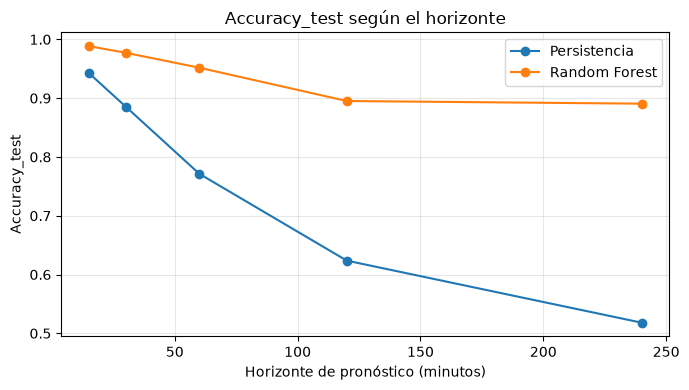

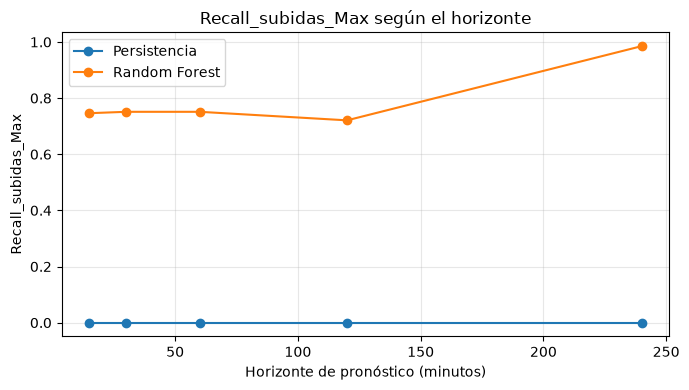

In [27]:
# Celda 10.2: desempeño según qué tan lejos se pronostica (15 min a 4 h)
curva_h = pr.curva_horizonte(df, horizontes=(1, 2, 4, 8, 16), params_rf=mejores_rf)
display(curva_h)
pr.graficar_horizonte(curva_h, "Accuracy_test");
pr.graficar_horizonte(curva_h, "Recall_subidas_Max");

**Cómo leer los gráficos.** Cada línea es un modelo (la persistencia y un Random Forest). El eje horizontal es **qué tan lejos se pronostica** (de 15 minutos a 4 horas) y el vertical, la métrica elegida (exactitud y recall de subidas a máxima).

**Cómo interpretarlos.** A corto plazo, "todo sigue igual" casi siempre acierta; a mayor plazo, la carga ya cambió. Por eso la persistencia empeora rápido y **la ventaja del modelo debería crecer con el horizonte**. También permite elegir el horizonte de la alerta: un plazo mayor da más tiempo para reaccionar, pero con menos certeza.

**Resultados.**

| Horizonte | Persistencia | Random Forest | Ventaja | Precisión carga máx. (RF) | Subidas anticipadas (RF) |
|---|---|---|---|---|---|
| 15 min | 0,943 | 0,988 | +4,6 | 0,974 | 0,746 |
| 30 min | 0,886 | 0,977 | +8,9 | 0,947 | 0,751 |
| **1 h** | 0,771 | 0,952 | +18,1 | 0,892 | 0,751 |
| 2 h | 0,624 | 0,895 | +27,2 | 0,787 | 0,721 |
| 4 h | 0,518 | 0,891 | +37,3 | 0,681 | 0,985 |

La persistencia cae de 0,943 a 0,518, mientras que el Random Forest se mantiene por sobre 0,89 incluso a 4 horas (se estabiliza entre 2 y 4 horas, porque el ciclo diario de la planta es regular). Por lo tanto, **la ventaja del modelo crece con el horizonte**: de 4,6 a 37,3 puntos. Al alejarse, la precisión de carga máxima baja (de 0,97 a 0,68), es decir, hay más falsas alarmas; el recall de subidas a 4 h (0,985) debe leerse con esa salvedad. **1 hora** es un equilibrio razonable entre tiempo de reacción y confiabilidad de la alerta.


## 11. Discusión y conclusiones

### 11.1 Cumplimiento de lo solicitado

| Requisito de la tarea | Dónde se cumple |
|---|---|
| Árboles de decisión con **Gini, entropía y error de clasificación** | Sección 5 (celda 5.1) |
| Graficar árboles con **3 y 5 niveles** de profundidad | Sección 5 (celda 5.2) |
| **Random Forest** | Sección 6 |
| **AdaBoost** | Sección 7 |
| **Redes bayesianas** | Sección 8 |
| Evaluación con **entrenamiento y prueba** | Todas las secciones (partición cronológica, sección 2.3) |
| Aplicación a los **datos del proyecto** | Pronóstico del nivel de carga de DAEWOO Steel Co. |

### 11.2 Resultados principales

1. **Criterios del árbol:** con profundidad 3, Gini, entropía y error de clasificación rinden prácticamente igual (0,78–0,79). Con profundidad 5 se separan: **Gini 0,898**, entropía 0,830 y error de clasificación 0,794. Pasar de 3 a 5 niveles mejora 11 puntos con Gini.
2. **Ensambles:** Random Forest (**0,952**) y AdaBoost (0,942) superan claramente al árbol de 5 niveles (0,898). Sin embargo, un árbol Gini de profundidad 8 ya alcanza 0,947 y un árbol único sin límite de profundidad, 0,954: la ventaja de los ensambles proviene sobre todo de la mayor profundidad y se traduce en estabilidad más que en exactitud.
3. **Red bayesiana:** la estructura aprendida (25 flechas) alcanza 0,843 de exactitud, la mejor de las tres estructuras, pero queda por debajo de los modelos de árboles. Aporta probabilidades explícitas y consultas por escenarios.
4. **Frente a las líneas base:** todos los modelos superan a la persistencia (0,771): Random Forest por +18,1 puntos, AdaBoost +17,0, árbol Gini +12,7 y red bayesiana +7,2.
5. **Alertas:** Random Forest anticipa el **75,1 %** de las subidas a carga máxima (604 de 804) con una precisión de 89,2 % al avisar carga máxima; AdaBoost anticipa el 65,1 %. La persistencia no anticipa ninguna.

### 11.3 Qué se puede rescatar de este trabajo

1. **Valor del consumo previo:** el mismo bosque sube de 0,722 (solo calendario) a **0,952** al conocer el consumo previo; las mediciones eléctricas no agregan nada adicional.
2. **Variables clave:** el pronóstico se apoya en **`Carga_actual`** (importancia por permutación de 0,38 en Random Forest y 0,46 en AdaBoost) y en la **hora del instante pronosticado** (0,21–0,23 cada componente). El consumo en sus distintos rezagos, la tendencia, las mediciones eléctricas y el tipo de día aportan poco una vez conocidas esas variables.
3. **Dónde está el límite:** la carga liviana se pronostica casi sin errores. Los errores se concentran en la frontera entre media y máxima y en los instantes de cambio de régimen: con Random Forest, los destinos cercanos a las 13–14 h y a las 22–23 h concentran los errores (cerca del 25–40 % de error en esas horas, frente a menos del 4 % en las demás).
4. **Modelo recomendado:** **Random Forest** para el sistema de alertas (mejor exactitud y mejor anticipación de subidas); un **árbol de decisión** como herramienta explicable, porque sus reglas pueden ser validadas por el personal de la planta; y la **red bayesiana** para analizar escenarios y definir umbrales de alerta, con la salvedad de los efectos de la discretización.
5. **Utilidad para el proyecto:** el modelo puede alimentar el sistema de alertas con un horizonte de **1 hora**, que da tiempo de reacción con una precisión de carga máxima de 0,89. Horizontes mayores aumentan el tiempo de reacción, pero con más falsas alarmas (sección 10.2).

### 11.4 Limitaciones

- Los datos corresponden a **un solo año y una sola planta**: los patrones podrían no generalizarse.
- El periodo de prueba (octubre–diciembre) es **distinto** al de entrenamiento: el calendario típico cae de 0,847 a 0,721 entre ambos, lo que sugiere un patrón horario diferente (posibles efectos estacionales).
- El calendario no considera **feriados**.
- El horizonte principal fue **1 hora**; otros horizontes se evaluaron solo con Random Forest (sección 10.2). La elección adecuada depende del tiempo que la planta necesite para reaccionar.
- Un único árbol sin límite de profundidad rinde tanto como el bosque (0,954 frente a 0,952): los ensambles aportan estabilidad, no necesariamente más exactitud.
- Los resultados de la red bayesiana **dependen de la discretización**.